## import ##

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
root="D:/Gdrive/publication/2023_DrinkingWater/fig/submission"

## Fig.1 ##

### (a) ALT & AST ###

In [4]:
df = pd.read_csv("D:/Gdrive/notebook/2209_DrinkingWaterModel/230901_TAA_MDA/drink_TAA_MDA_chronic.csv")
df = df.iloc[0:33, :]
df

,No.,group,BW,ALT,AST,BW.1,ALT.1,AST.1,TBIL,BW.2,ALT.2,AST.2,TBIL.1
0,1,Control,21.25,27,52,22.40,24,29,0.1,NaN,NaN,NaN,NaN
1,2,Control,21.93,23,41,22.55,25,45,0.1,NaN,NaN,NaN,NaN
2,3,Control,20.15,28,42,20.83,24,27,0.1,NaN,NaN,NaN,NaN
3,4,Control,21.47,24,45,22.67,21,31,0.1,NaN,NaN,NaN,NaN
4,5,Control,20.43,25,40,21.50,33,36,NaN,23.78,24.0,32.0,0.1
5,6,Control,20.34,28,42,21.60,26,36,NaN,23.47,24.0,33.0,0.1
6,7,Control,20.30,24,44,22.17,24,40,NaN,23.92,25.0,31.0,0.1
7,8,Control,20.75,27,49,21.70,30,51,NaN,23.72,24.0,34.0,0.1
8,9,TAA,17.15,170,174,19.06,186,145,0.2,NaN,NaN,NaN,NaN
9,10,TAA,17.39,329,290,20.40,97,116,0.2,NaN,NaN,NaN,NaN


In [5]:
df_ALT = df.loc[:, df.columns.str.contains("ALT")]
df_AST = df.loc[:, df.columns.str.contains("AST")]
df_ALT = df_ALT.rename(columns={'ALT':'day7', 'ALT.1':'day14', 'ALT.2':'day28'})
df_AST = df_AST.rename(columns={'AST':'day7', 'AST.1':'day14', 'AST.2':'day28'})

In [7]:
def plot_line(df, name="ALT", figname=None):
    """Returns bar plot

    Parameters:
    ----------
    df : pd.DataFrame
        Information Data (ALT)

    """
    fig = plt.figure(figsize=(7, 5))
    ax = fig.add_subplot(111)

    for i in range(len(df)):
        x = [float(i.split("y")[1]) for i in df.columns.tolist()]
        y = np.array(df.loc[[i], :].values.tolist()[0])
        if i < 4:
            pass
            #plt.plot(x, y, color = 'gray', marker = 'o')
        elif i == 4:
            plt.plot(x, y, color = 'gray', marker = 'o', label="Control")
        elif i < 8:
            plt.plot(x, y, color = 'gray', marker = 'o')
        elif i < 14:
            #plt.plot(x, y, color = 'green', marker = 'v')
            pass
        elif i == 14:
            plt.plot(x, y, color = 'orangered', marker = 'v', label="TAA")
        elif i < 20:
            plt.plot(x, y, color = 'orangered', marker = 'v')
        elif i < 26:
            #plt.plot(x, y, color = 'deepskyblue', marker = '^')
            pass
        elif i == 26:
            plt.plot(x, y, color = 'mediumblue', marker = '^', label="MDA")
        elif i < 32:
            plt.plot(x, y, color = 'mediumblue', marker = '^')

    ax.set_xlabel("day", fontsize=17)
    ax.set_ylabel(name+" (U/L)", fontsize=17)
    ax.legend(loc="upper right", fontsize=15)
    ax.set_title("ALT changes over time", fontsize=21)

    #ax.set_ylim(0, 500)

    ax.grid(False)
    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    ax.tick_params(axis='x', labelsize=18)
    ax.tick_params(axis='y', labelsize=18)

    plt.tick_params(bottom=False, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    if figname:
        plt.savefig(figname, dpi=300)
    plt.show()

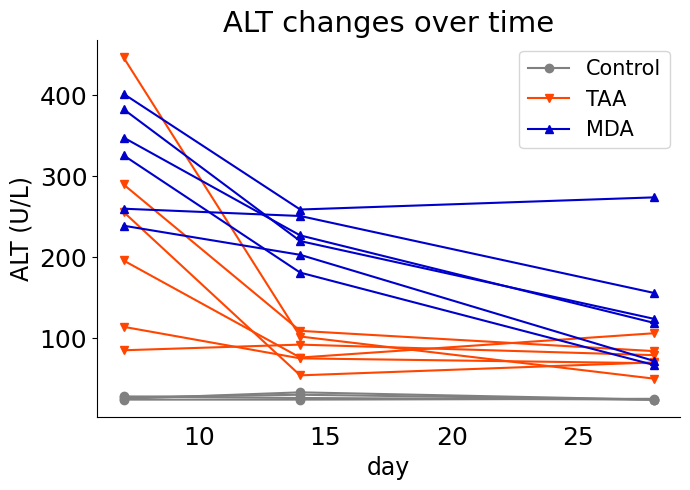

In [9]:
plot_line(df_ALT, figname=f"{root}/fig1a.png")

### (b) qPCR ###

In [14]:
from scipy import stats

#### day14 ####

In [10]:
df = pd.read_csv("D:/Gdrive/notebook/2209_DrinkingWaterModel/230901_TAA_MDA/231020_dw_day14_fib_2309sample_v2 -  Quantification Cq Results.csv", index_col=0)
df.head()

,Well,Fluor,Target,Content,Sample,Biological Set Name,Cq,Cq Mean,Cq Std. Dev,Starting Quantity (SQ),Log Starting Quantity,SQ Mean,SQ Std. Dev,Set Point,Well Note
NaN,A02,SYBR,18S,Unkn,Ctrl_2,NaN,14.054805,14.054805,0,3.531776e-04,-3.452007,3.531776e-04,0,72,NaN
NaN,A03,SYBR,18S,Unkn,Ctrl_4,NaN,15.051839,15.051839,0,1.981468e-04,-3.703013,1.981468e-04,0,72,NaN
NaN,A05,SYBR,GAPDH,Unkn,Ctrl_2,NaN,21.751976,21.751976,0,7.670346e-06,-5.115185,7.670346e-06,0,72,NaN
NaN,A06,SYBR,GAPDH,Unkn,Ctrl_4,NaN,22.454160,22.454160,0,5.103382e-06,-5.292142,5.103382e-06,0,72,NaN
NaN,A08,SYBR,Col1a1,Unkn,Ctrl_2,NaN,31.659890,31.659890,0,5.761428e-07,-6.239470,5.761428e-07,0,72,NaN


In [11]:
df_sq = pd.DataFrame()

# sampleとgeneのリストを取得
sample_lst = [i for i in set(df.loc[:, "Sample"].tolist()) if str(i) != "nan"]
gene_lst = [i for i in set(df.loc[:, "Target"].tolist()) if str(i) != "nan"]

# SQのみを抽出
for sample in sample_lst:
    for gene in gene_lst:
        df_sq.loc[gene, sample] = df[df["Sample"] == sample][df[df["Sample"] == sample]["Target"] == gene].loc[:, "Starting Quantity (SQ)"].iloc[-1]

df_sq = df_sq.sort_index(axis=1)

In [12]:
internal_standard="GAPDH"
df_sq_is = (df_sq/df_sq.loc[internal_standard, :].tolist())
df_ctrl_acta2 = df_sq_is.loc["Acta2", df_sq_is.columns.str.contains("Ctrl")]
df_taa_acta2 = df_sq_is.loc["Acta2", df_sq_is.columns.str.contains("TAA")]
df_mda_acta2 = df_sq_is.loc["Acta2", df_sq_is.columns.str.contains("MDA")]
df_ctrl_col1a1 = df_sq_is.loc["Col1a1", df_sq_is.columns.str.contains("Ctrl")]
df_taa_col1a1 = df_sq_is.loc["Col1a1", df_sq_is.columns.str.contains("TAA")]
df_mda_col1a1 = df_sq_is.loc["Col1a1", df_sq_is.columns.str.contains("MDA")]

In [15]:
t_taa_acta2, p_taa_acta2 =stats.ttest_ind(df_ctrl_acta2, df_taa_acta2, alternative="two-sided", equal_var=False)
print(p_taa_acta2)
t_mda_acta2, p_mda_acta2 =stats.ttest_ind(df_ctrl_acta2, df_mda_acta2, alternative="two-sided", equal_var=False)
print(p_mda_acta2*2)
t_taa_col1a1, p_taa_col1a1 =stats.ttest_ind(df_ctrl_col1a1, df_taa_col1a1, alternative="two-sided", equal_var=False)
print(p_taa_col1a1*2)
t_mda_col1a1, p_mda_col1a1 =stats.ttest_ind(df_ctrl_col1a1, df_mda_col1a1, alternative="two-sided", equal_var=False)
print(p_mda_col1a1)

0.22891974279529576
0.018735859345563
0.00428798758675602
0.03026050412637803


#### day 28 ####

In [16]:
df_2 = pd.read_csv("D:/Gdrive/notebook/2209_DrinkingWaterModel/230901_TAA_MDA/231023_dw_day28_fib_2309sample -  Quantification Cq Results.csv", index_col=0)
df_2.head()

,Well,Fluor,Target,Content,Sample,Biological Set Name,Cq,Cq Mean,Cq Std. Dev,Starting Quantity (SQ),Log Starting Quantity,SQ Mean,SQ Std. Dev,Set Point,Well Note
NaN,A02,SYBR,18S,Unkn,Ctrl_6,NaN,11.891418,11.891418,0,5.002710e-01,-0.300795,5.002710e-01,0,72,NaN
NaN,A03,SYBR,18S,Unkn,Ctrl_8,NaN,32.109311,32.109311,0,1.236047e-11,-10.907965,1.236047e-11,0,72,NaN
NaN,A05,SYBR,GAPDH,Unkn,Ctrl_6,NaN,22.667687,22.667687,0,5.423857e-05,-4.265692,5.423857e-05,0,72,NaN
NaN,A06,SYBR,GAPDH,Unkn,Ctrl_8,NaN,22.230721,22.230721,0,6.531601e-05,-4.184980,6.531601e-05,0,72,NaN
NaN,A08,SYBR,Col1a1,Unkn,Ctrl_6,NaN,31.329038,31.329038,0,6.623730e-06,-5.178897,6.623730e-06,0,72,NaN


In [17]:
df_sq_2 = pd.DataFrame()

# sampleとgeneのリストを取得
sample_lst = [i for i in set(df_2.loc[:, "Sample"].tolist()) if str(i) != "nan"]
gene_lst = [i for i in set(df_2.loc[:, "Target"].tolist()) if str(i) != "nan"]

# SQのみを抽出
for sample in sample_lst:
    for gene in gene_lst:
        df_sq_2.loc[gene, sample] = df_2[df_2["Sample"] == sample][df_2[df_2["Sample"] == sample]["Target"] == gene].loc[:, "Starting Quantity (SQ)"].iloc[-1]

df_sq_2 = df_sq_2.sort_index(axis=1)

In [18]:
internal_standard="GAPDH"
df_sq_2_is = (df_sq_2/df_sq_2.loc[internal_standard, :].tolist())
df_ctrl_acta2 = df_sq_2_is.loc["Acta2", df_sq_2_is.columns.str.contains("Ctrl")]
df_taa_acta2 = df_sq_2_is.loc["Acta2", df_sq_2_is.columns.str.contains("TAA")]
df_mda_acta2 = df_sq_2_is.loc["Acta2", df_sq_2_is.columns.str.contains("MDA")]
df_ctrl_col1a1 = df_sq_2_is.loc["Col1a1", df_sq_2_is.columns.str.contains("Ctrl")]
df_taa_col1a1 = df_sq_2_is.loc["Col1a1", df_sq_2_is.columns.str.contains("TAA")]
df_mda_col1a1 = df_sq_2_is.loc["Col1a1", df_sq_2_is.columns.str.contains("MDA")]

In [19]:
t_taa_acta2, p_taa_acta2 =stats.ttest_ind(df_ctrl_acta2, df_taa_acta2, alternative="two-sided", equal_var=False)
print(p_taa_acta2)
t_mda_acta2, p_mda_acta2 =stats.ttest_ind(df_ctrl_acta2, df_mda_acta2, alternative="two-sided", equal_var=False)
print(p_mda_acta2*2)
t_taa_col1a1, p_taa_col1a1 =stats.ttest_ind(df_ctrl_col1a1, df_taa_col1a1, alternative="two-sided", equal_var=False)
print(p_taa_col1a1)
t_mda_col1a1, p_mda_col1a1 =stats.ttest_ind(df_ctrl_col1a1, df_mda_col1a1, alternative="two-sided", equal_var=False)
print(p_mda_col1a1*2)

0.5251364813162736
0.0009067920119094354
0.08928236771279047
0.012244375968453616


#### plot ####

In [20]:
def sq_plot2(df_lst, internal_standard="", target_gene="", y_max=0, figname=None):
    fig = plt.figure(figsize=(7, 7))
    for i, df_sq in enumerate(df_lst):
        df_sq_is = (df_sq/df_sq.loc[internal_standard, :].tolist()).T
        
        df_ctrl = df_sq_is.loc[[i.split("_")[0] == "Ctrl" for i in df_sq_is.index.tolist()], :]
        df_ctrl = df_ctrl.loc[:, [target_gene]]

        df_taa = df_sq_is.loc[[i.split("_")[0] == "TAA" for i in df_sq_is.index.tolist()], :]
        df_taa = df_taa.loc[:, [target_gene]]

        df_mda = df_sq_is.loc[[i.split("_")[0] == "MDA" for i in df_sq_is.index.tolist()], :]
        df_mda = df_mda.loc[:, [target_gene]]

        ax = fig.add_subplot(1, 2, i+1)
        ax2 = ax.twinx()

        width = 0.25
        x_position = np.arange(len(df_ctrl.columns))
        error_bar_set = dict(lw = 1, capthick = 1, capsize = 4)
        ax.bar(x_position-width, df_ctrl.mean(), yerr=df_ctrl.std(), tick_label=df_ctrl.columns, error_kw=error_bar_set, color='gray', width=0.97*width, label="Ctrl", alpha=.8)
        ax.bar(x_position+width, df_mda.mean(), yerr=df_mda.std(), tick_label=df_ctrl.columns, error_kw=error_bar_set, color='royalblue', width=0.97*width, label="MDA", alpha=.8)
        ax.bar(x_position, df_taa.mean(), yerr=df_taa.std(), tick_label=df_ctrl.columns, error_kw=error_bar_set, color='coral', width=0.97*width, label="TAA", alpha=.8)

        ax.legend(fontsize=18, loc="upper right")
        plt.grid(False)
        [ax.spines[side].set_visible(False) for side in ['right','top']]

        # jitter plot
        df_melt1 = pd.melt(df_ctrl)
        df_melt1['dose'] = 'Ctrl'
        df_melt2 = pd.melt(df_taa)
        df_melt2['dose'] = 'TAA'
        df_melt3 = pd.melt(df_mda)
        df_melt3['dose'] = 'MDA'
        df_melt = pd.concat([df_melt1, df_melt2, df_melt3], axis=0)

        sns.stripplot(x='variable', y='value', data=df_melt, hue='dose', dodge=True, jitter=True, s=7, linewidth=1, ec="black", palette=['black', 'orangered', 'mediumblue'], ax=ax2)

        if i == 0:
            ax.set_ylabel("SQ (raito, IS = "+internal_standard+")", fontsize=20)
            ax.set_xticklabels(["day14"])
            ax.get_legend().remove()         
        elif i == 1:
            ax.set_xticklabels(["day28"])

        ax.tick_params(axis='x', labelsize=16, direction='in', width=0)
        ax.tick_params(axis='y', labelsize=16)

        ax.set_ylim(0,y_max)
        ax2.set_ylim(0,y_max)

        ax2.axis("off")
        ax2.get_legend().remove()

    fig.suptitle(target_gene, fontsize=24)
    plt.tight_layout()
    if figname:
        plt.savefig(figname, dpi=300)
    plt.show()

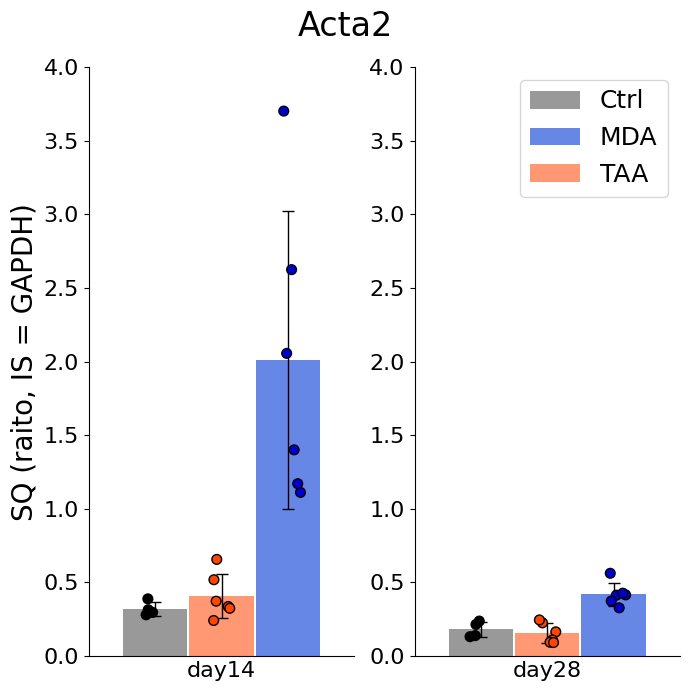

In [21]:
sq_plot2([df_sq, df_sq_2], internal_standard="GAPDH", target_gene="Acta2", y_max=4.0, figname=f"{root}/fig1b1.png")

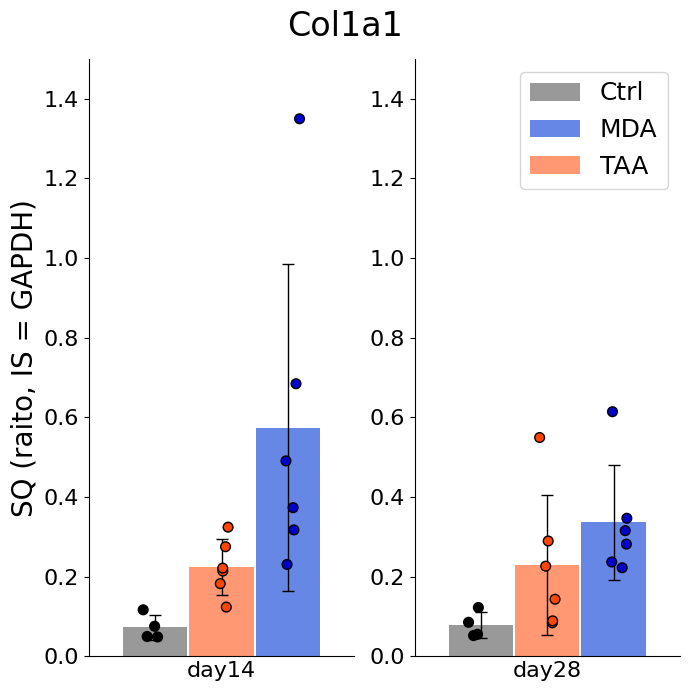

In [22]:
sq_plot2([df_sq, df_sq_2], internal_standard="GAPDH", target_gene="Col1a1", y_max=1.5, figname=f"{root}/fig1b2.png")

## Fig.4 ##

### (a) ALT & AST ###

In [23]:
df = pd.read_csv("D:/Gdrive/notebook/2209_DrinkingWaterModel/221212_TAA_MDA/rawdata/rawdata.csv", index_col=0)
df = df.iloc[:, 0:15]
df_ALT = df.loc[:, df.columns.str.contains("ALT")]
df_AST = df.loc[:, df.columns.str.contains("AST")]
df_ALT = df_ALT.rename(columns={'ALT':'day1', 'ALT.1':'day2', 'ALT.2':'day3', 'ALT.3':'day4', 'ALT.4':'day8'})
df_AST = df_AST.rename(columns={'AST':'day1', 'AST.1':'day2', 'AST.2':'day3', 'AST.3':'day4', 'AST.4':'day8'})
df_BW = df.loc[:, df.columns.str.contains("BW")]
df_BW = df_BW.rename(columns={'BW':'day1', 'BW.1':'day2', 'BW.2':'day3', 'BW.3':'day4', 'BW.4':'day8'})

df_ALT_control = df_ALT.iloc[0:4, :]
df_ALT_TAA = df_ALT.iloc[4:12, :]
df_ALT_MDA = df_ALT.iloc[12:20, :]

df_AST_control = df_AST.iloc[0:4, :]
df_AST_TAA = df_AST.iloc[4:12, :]
df_AST_MDA = df_AST.iloc[12:20, :]

df_BW_control = df_BW.iloc[0:4, :]
df_BW_TAA = df_BW.iloc[4:12, :]
df_BW_MDA = df_BW.iloc[12:20, :]

In [24]:
def barplot5(df_ALT, df_AST, title='', lim=1000, figname=None):
    df_ALT = df_ALT/1000
    df_AST = df_AST/1000
    plt.style.use('default')
    sns.set()
    sns.set_style('whitegrid')
    sns.set_palette('gist_yarg')

    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(1, 1, 1)
    ax2 = ax.twinx()

    # bar chart & error bar
    width = 0.45
    x_position = np.arange(len(df_ALT.columns))
    error_bar_set = dict(lw = 1, capthick = 1, capsize = 4)
    ax.bar(x_position-width/2, df_ALT.mean(), yerr=df_ALT.std(), tick_label=df_ALT.columns, error_kw=error_bar_set, color='gray', width=width, label="ALT")
    ax.bar(x_position+width/2, df_AST.mean(), yerr=df_AST.std(), tick_label=df_ALT.columns, error_kw=error_bar_set, color='silver', width=width, label="AST")

    ax.legend(fontsize=18)
    plt.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    # jitter plot
    df_melt1 = pd.melt(df_ALT)
    df_melt1['dose'] = 'ALT'
    df_melt2 = pd.melt(df_AST)
    df_melt2['dose'] = 'AST'
    df_melt = pd.concat([df_melt1, df_melt2], axis=0)

    sns.stripplot(x='variable', y='value', data=df_melt, hue='dose', dodge=True, jitter=True, palette=['black', 'black'], marker='o', ax=ax2, s=7)

    ax.set_xticklabels([i.split("y")[1] + " day" for i in df_ALT.columns.tolist()], rotation=45, fontsize=20)
    #ax.set_yticks([0, 10, 20, 30, 40], fontsize=20)
    ax.set_ylabel('ALT & AST (x10^3 U/l)', fontsize=22)
    ax.set_title(title, fontsize=24)

    ax.set_ylim(0,lim)
    ax2.set_ylim(0,lim)
    ax2.axis("off")
    ax2.get_legend().remove()
    [ax2.spines[side].set_visible(False) for side in ['right','top']]

    ax.grid(False)
    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    ax.tick_params(axis='y', labelsize=18)

    plt.tick_params(bottom=False, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    if figname:
        plt.savefig(figname, dpi=300)

    plt.show()

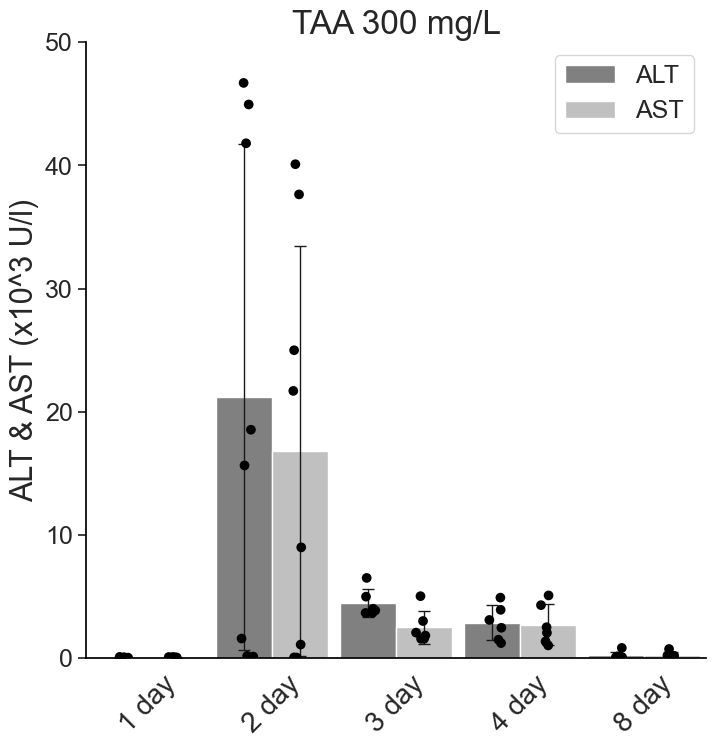

In [25]:
barplot5(df_ALT_TAA, df_AST_TAA, title='TAA 300 mg/L', lim=50, figname=f"{root}/fig4a1.png")

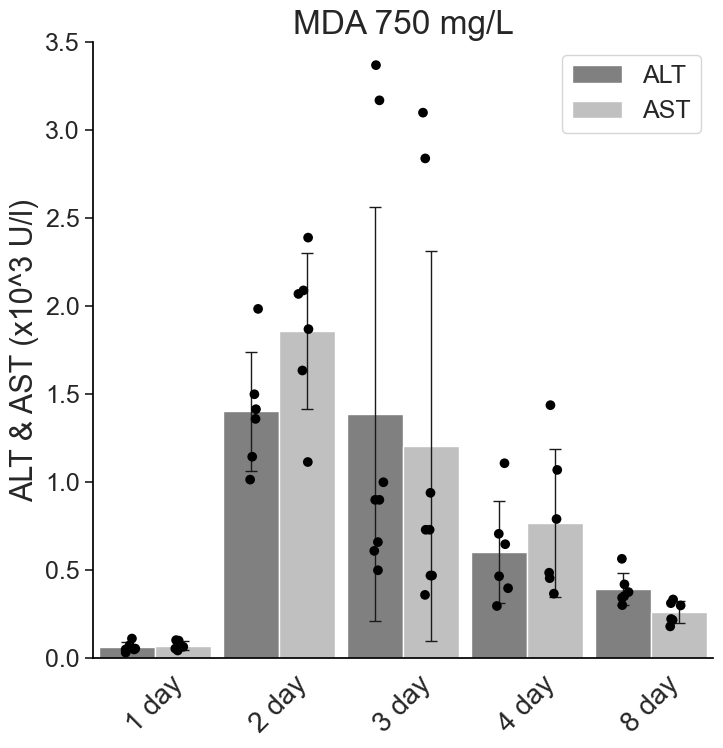

In [26]:
barplot5(df_ALT_MDA, df_AST_MDA, title='MDA 750 mg/L', lim=3.5, figname=f"{root}/fig4a2.png")

### (b, c) TBIL & TCHO  ###

In [31]:
def barplot6(df_ctrl, df_MDA, df_TAA, title='', lim=1000, figname=None):
    plt.style.use('default')
    sns.set()
    sns.set_style('whitegrid')
    sns.set_palette('gist_yarg')

    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(1, 1, 1)
    ax2 = ax.twinx()

    # bar chart & error bar
    width = 0.25
    x_position = np.arange(len(df_ctrl.columns))
    error_bar_set = dict(lw = 1, capthick = 1, capsize = 4)
    ax.bar(x_position-width, df_ctrl.mean(), yerr=df_ctrl.std(), tick_label=df_ctrl.columns, error_kw=error_bar_set, color='gray', width=0.97*width, label="Ctrl", alpha=.8)
    ax.bar(x_position+width, df_MDA.mean(), yerr=df_MDA.std(), tick_label=df_ctrl.columns, error_kw=error_bar_set, color='royalblue', width=0.97*width, label="MDA", alpha=.8)
    ax.bar(x_position, df_TAA.mean(), yerr=df_TAA.std(), tick_label=df_ctrl.columns, error_kw=error_bar_set, color='coral', width=0.97*width, label="TAA", alpha=.8)

    ax.legend(fontsize=18, loc="upper left")
    plt.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    # jitter plot
    df_melt1 = pd.melt(df_ctrl)
    df_melt1['dose'] = 'Ctrl'
    df_melt2 = pd.melt(df_TAA)
    df_melt2['dose'] = 'TAA'
    df_melt3 = pd.melt(df_MDA)
    df_melt3['dose'] = 'MDA'
    df_melt = pd.concat([df_melt1, df_melt2, df_melt3], axis=0)

    sns.stripplot(x='variable', y='value', data=df_melt, hue='dose', dodge=True, jitter=True, s=7, linewidth=1, ec="black", palette=['black', 'orangered', 'mediumblue'], ax=ax2)

    ax.set_xticklabels([i.split("y")[1] + " day" for i in df_ctrl.columns.tolist()], rotation=45, fontsize=20)
    #ax.set_yticks([0, 10, 20, 30, 40], fontsize=20)
    ax.set_ylabel(title+' (mg/dl)', fontsize=22)
    ax.set_title(title, fontsize=24)

    ax.set_ylim(0,lim)
    ax2.set_ylim(0,lim)
    ax2.axis("off")
    ax2.get_legend().remove()
    [ax2.spines[side].set_visible(False) for side in ['right','top']]

    ax.grid(False)
    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    ax.tick_params(axis='y', labelsize=18)

    plt.tick_params(bottom=False, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    if figname:
        plt.savefig(figname, dpi=300)

    plt.show()

In [32]:
df_tbil = pd.read_csv("D:/Gdrive/notebook/2209_DrinkingWaterModel/221212_TAA_MDA/rawdata/rawdata_tbil.csv", index_col=0)
df_tbil_control = df_tbil.iloc[0:4, :]
df_tbil_TAA = df_tbil.iloc[4:12, :]
df_tbil_MDA = df_tbil.iloc[12:20, :]

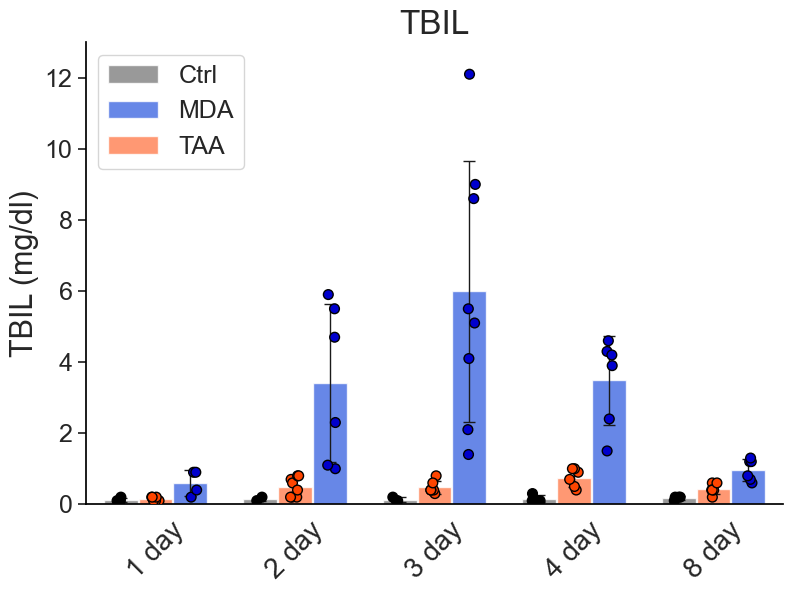

In [33]:
barplot6(df_tbil_control, df_tbil_MDA, df_tbil_TAA, title='TBIL', lim=13, figname=f"{root}/fig4b.png")

In [35]:
df_tcho = pd.read_csv("D:/Gdrive/notebook/2209_DrinkingWaterModel/221212_TAA_MDA/rawdata/rawdata_tcho.csv", index_col=0)
df_tcho_control = df_tcho.iloc[0:4, :]
df_tcho_TAA = df_tcho.iloc[4:12, :]
df_tcho_MDA = df_tcho.iloc[12:20, :]

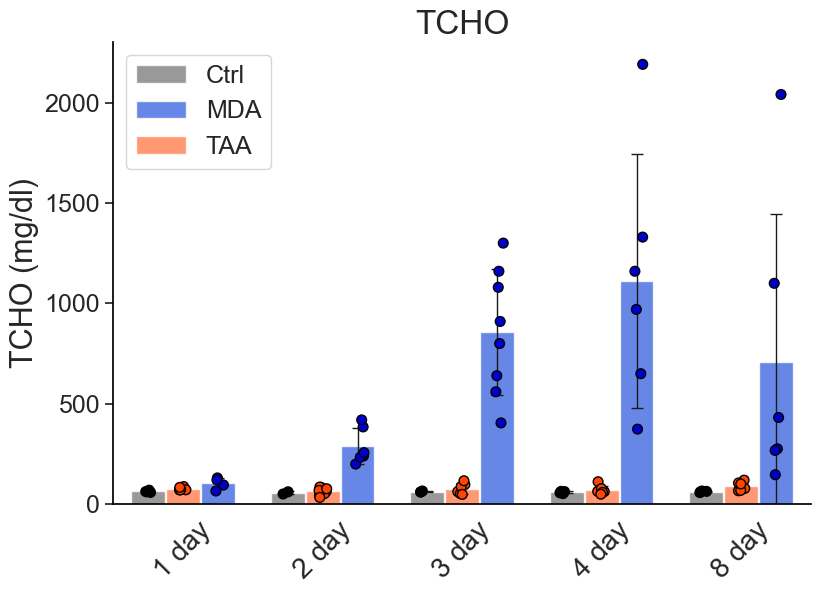

In [41]:
barplot6(df_tcho_control, df_tcho_MDA, df_tcho_TAA, title='TCHO', lim=2300, figname=f"{root}/fig4c.png")

### (Fig.S1) ###

In [37]:
df_tg = pd.read_csv("D:/Gdrive/notebook/2209_DrinkingWaterModel/221212_TAA_MDA/rawdata/rawdata_tg.csv", index_col=0)
df_tg = df_tg.iloc[:, 0:5]
df_tg_control = df_tg.iloc[0:4, :]
df_tg_TAA = df_tg.iloc[4:12, :]
df_tg_MDA = df_tg.iloc[12:20, :]

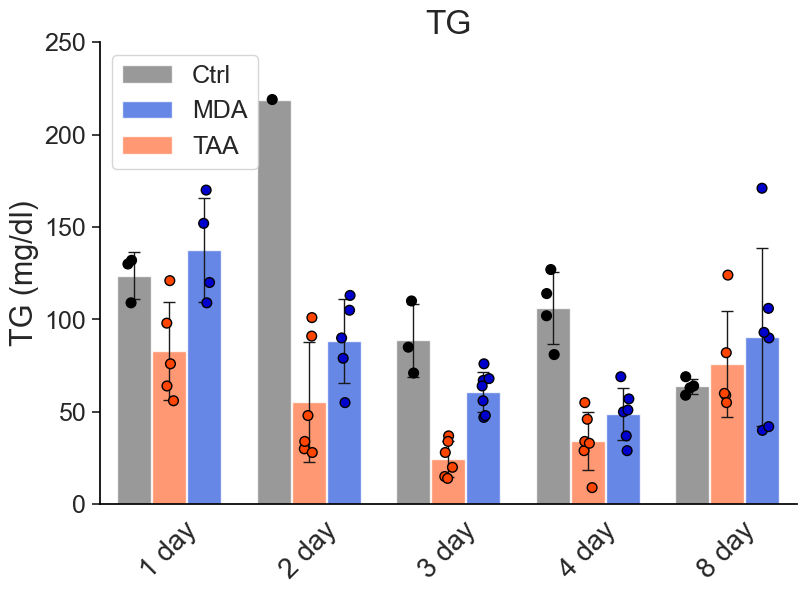

In [42]:
barplot6(df_tg_control, df_tg_MDA, df_tg_TAA, title='TG', lim=250, figname=f"{root}/figs1a.png")

In [39]:
df_hdl = pd.read_csv("D:/Gdrive/notebook/2209_DrinkingWaterModel/221212_TAA_MDA/rawdata/rawdata_hdl.csv", index_col=0)
df_hdl = df_hdl.iloc[:, 0:5]
df_hdl_control = df_hdl.iloc[0:4, :]
df_hdl_TAA = df_hdl.iloc[4:12, :]
df_hdl_MDA = df_hdl.iloc[12:20, :]

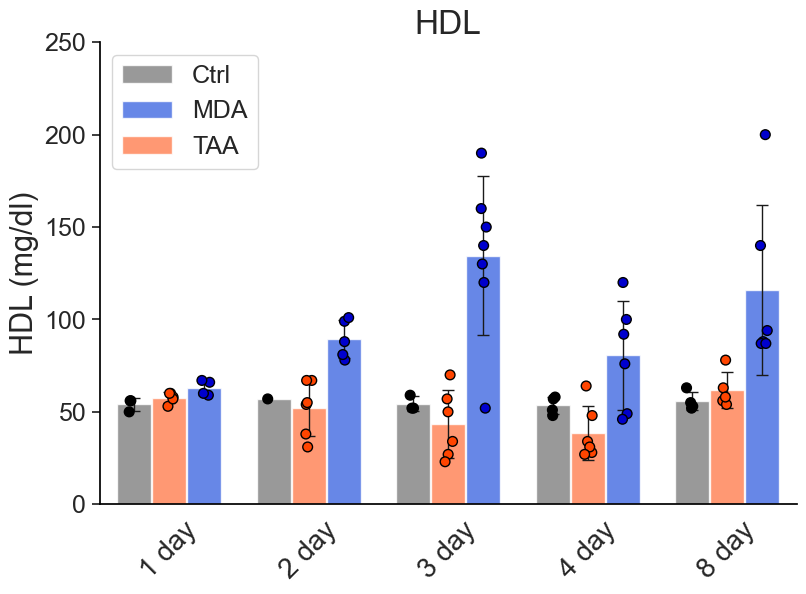

In [43]:
barplot6(df_hdl_control, df_hdl_MDA, df_hdl_TAA, title='HDL', lim=250, figname=f"{root}/figs1b.png")

## Fig.5 ##

### (a), (Fig.S2) facs ###

In [3]:
flatui = ["orangered", "mediumblue"]
sns.set_palette(flatui)
sns.color_palette(n_colors=2)

[(1.0, 0.27058823529411763, 0.0), (0.0, 0.0, 0.803921568627451)]

In [15]:
def violinplot_twogroup(df_dili, immune='', celltype='', figname=None):
    fig = plt.figure(figsize=(5, 5))
    ax = fig.add_subplot(1, 1, 1)

    flatui = ["coral", "royalblue"]
    sns.set_palette(flatui)
    sns.violinplot(data=df_dili, x='day', y=immune, inner=None, hue='group', split=True)

    if celltype == "lymph":
        fig.legend(frameon=True, loc=(0.715, 0.75), fontsize=14, framealpha=1)
    elif celltype == "mye":
        fig.legend(frameon=True, loc=(0.25, 0.75), fontsize=14, framealpha=1)

    flatui = ["orangered", "mediumblue"]
    sns.set_palette(flatui)
    sns.swarmplot(data=df_dili, x='day', y=immune, size=5, linewidth=1, ec="black", hue='group', dodge=False)

    ax.get_legend().remove()

    plt.grid(False)
    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)
    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')
    ax.set_title(immune, fontsize=24)
    ax.set_xlabel("day", fontsize=20)
    ax.set_ylabel("population", fontsize=20)
    ax.tick_params(axis='x', labelsize=16)
    ax.tick_params(axis='y', labelsize=16)

    plt.tight_layout()
    if figname:
        plt.savefig(figname, dpi=300)
    plt.show()

In [5]:
df_total = pd.read_csv("D:/GDRIVE/notebook/2209_DrinkingWaterModel/221212_TAA_MDA/FACS/230605_data_blood_facs.csv", index_col=0)

In [6]:
col_lst = []
ap = col_lst.append
for col in df_total.columns.tolist():
    if col == "neutrophil" or col == "eosinophil":
        ap(col.capitalize())
    else:
        ap(col)
df_total.columns = col_lst
print(col_lst)

['ID', 'group', 'day', 'BW', 'ALT', 'AST', 'water batch', 'RNAbatch', 'total RNA concentration (ng/ul)', 'plasma availability', 'note', 'gdT', 'NKT', 'NK', 'CD4T', 'CD8T', 'B', 'Monocyte', 'Neutrophil', 'Kupffer', 'Eosinophil', 'MonMac']


In [7]:
df_dili = df_total[~df_total.loc[:, "group"].str.contains("Control")]
df_dili.head()

,ID,group,day,BW,ALT,AST,water batch,RNAbatch,total RNA concentration (ng/ul),plasma availability,...,NKT,NK,CD4T,CD8T,B,Monocyte,Neutrophil,Kupffer,Eosinophil,MonMac
No.,,,,,,,,,,,,,,,,,,,,,
19,1T1,TAA,1,20.19,32,44,TAA 400,1220pm,168.9,1,...,0.006626,0.059432,0.124571,0.033397,0.155780,0.042563,0.025674,0.309731,0.019041,0.031955
20,1T2,TAA,1,20.90,112,103,TAA 400,1220pm,151.6,1,...,0.007345,0.069436,0.086689,0.033285,0.176153,0.142711,0.043024,0.226280,0.040880,0.027008
21,1T3,TAA,1,21.17,50,58,TAA 400,1220pm,206.4,1,...,0.004684,0.057611,0.098674,0.028996,0.169064,0.065248,0.024086,0.337807,0.015618,0.024248
22,1T4,TAA,1,20.28,74,100,TAA 400,1221am,161.8,1,...,0.003834,0.053892,0.097386,0.028617,0.161134,0.083147,0.030045,0.315845,0.024671,0.027456
23,1T5,TAA,1,22.09,50,55,TAA 400,1221am,59.5,1,...,0.003455,0.054543,0.113385,0.028588,0.160524,0.072353,0.019659,0.328845,0.019614,0.023893


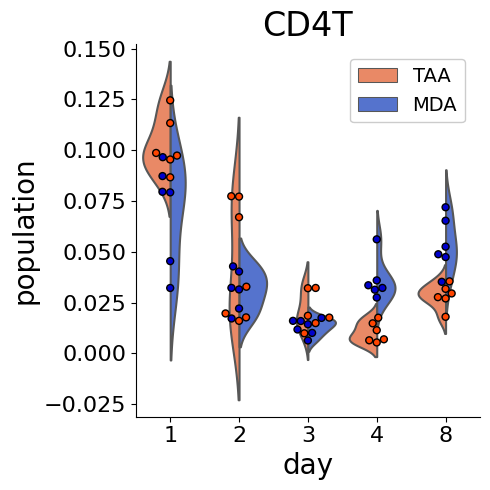

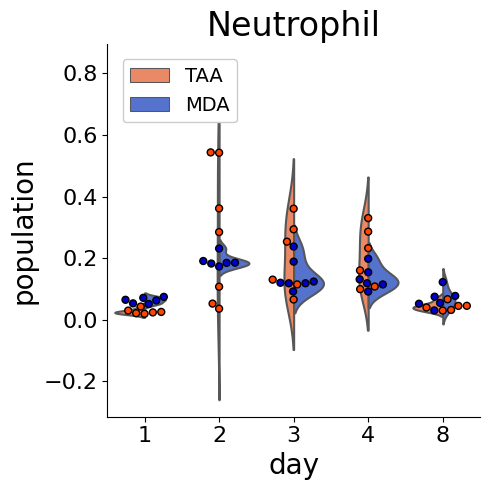

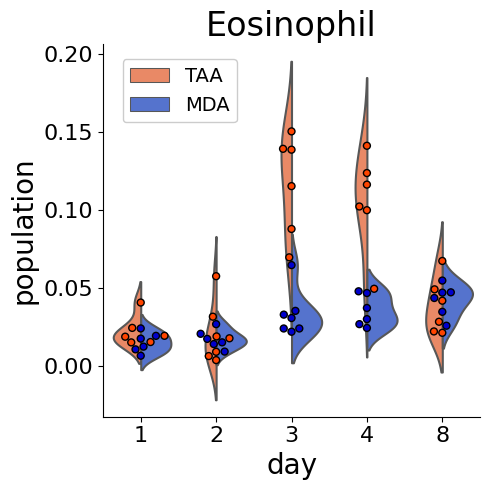

c:\Users\2022_iwasaka\miniconda3\envs\standerd\lib\site-packages\seaborn\categorical.py:1296: UserWarning: 8.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


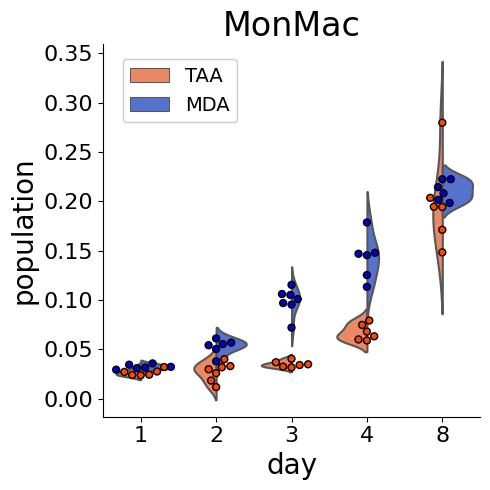

In [16]:
target = [
 'CD4T',
 'Neutrophil',
 'Eosinophil',
 'MonMac'
 ]
for n, i in enumerate(target):
    fig_name = "fig5a"+str(n+1)+".png"
    name = f"{root}/{fig_name}"
    if i == "CD4T":
        violinplot_twogroup(df_dili, immune=i, celltype='lymph', figname=name)
    else:
        violinplot_twogroup(df_dili, immune=i, celltype='mye', figname=name)

c:\Users\2022_iwasaka\miniconda3\envs\standerd\lib\site-packages\seaborn\categorical.py:1296: UserWarning: 35.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


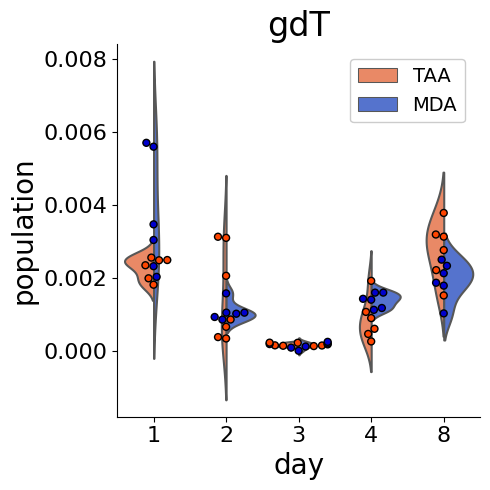

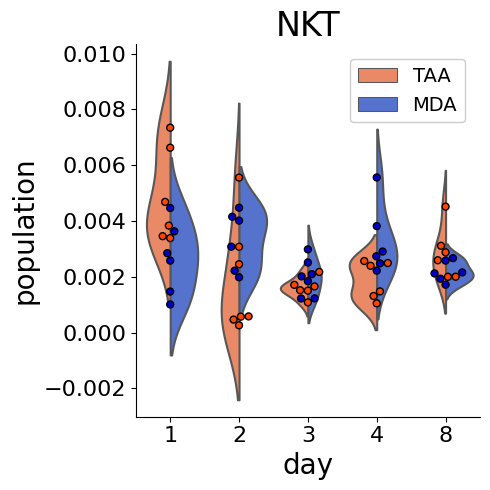

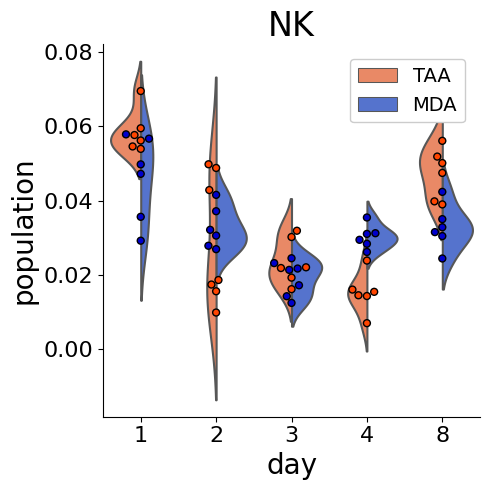

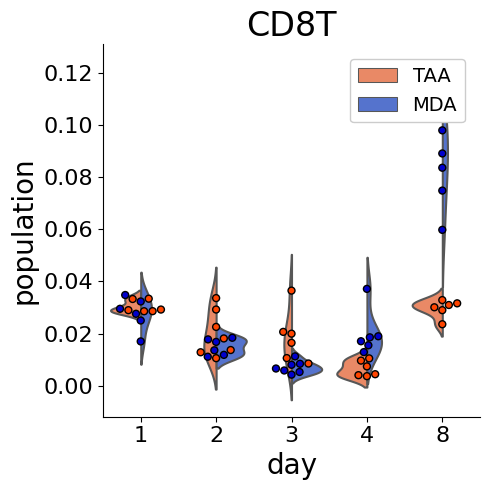

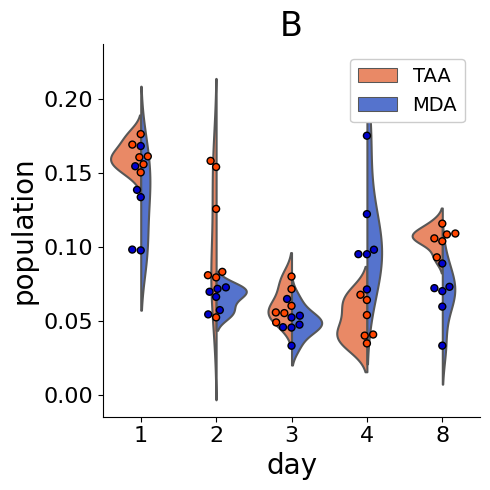

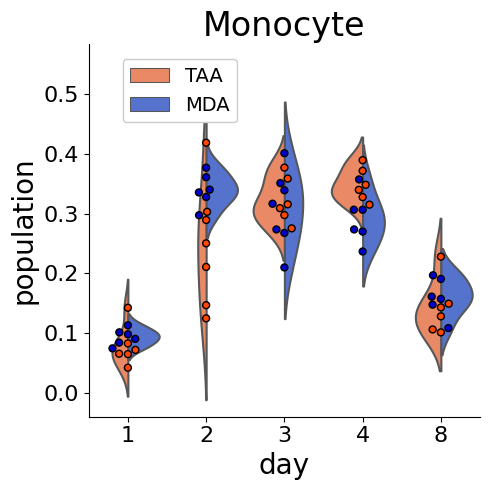

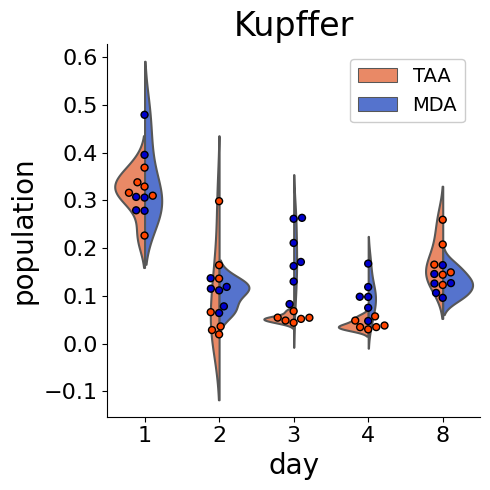

In [17]:
target = [
 'gdT',
 'NKT',
 'NK',
 'CD8T',
 'B',
 'Monocyte',
 'Kupffer',
 ]
for n, i in enumerate(target):
    fig_name = "figs2a"+str(n+1)+".png"
    name = f"{root}/{fig_name}"
    if i == "Monocyte":
        violinplot_twogroup(df_dili, immune=i, celltype='mye', figname=name)
    else:
        violinplot_twogroup(df_dili, immune=i, celltype='lymph', figname=name)

### (b) scatter (ALT & Neutrophil) ###

In [18]:
plt.style.use('default')
sns.set()
sns.set_style('whitegrid')
sns.set_palette('gist_yarg')

In [25]:
df_total.head()

,ID,group,day,BW,ALT,AST,water batch,RNAbatch,total RNA concentration (ng/ul),plasma availability,...,NKT,NK,CD4T,CD8T,B,Monocyte,Neutrophil,Kupffer,Eosinophil,MonMac
No.,,,,,,,,,,,,,,,,,,,,,
1,1C1,Control,1,22.11,21,30,tap water,1220pm,82.6,1,...,0.002640,0.046542,0.072551,0.033412,0.164993,0.017147,0.018556,0.477411,0.011294,0.022464
2,1C2,Control,1,20.99,29,38,tap water,1220pm,36.3,1,...,0.003991,0.053364,0.081842,0.042128,0.131633,0.017804,0.014358,0.456299,0.017804,0.021420
3,1C3,Control,1,22.18,20,31,tap water,1221am,118.0,1,...,0.006526,0.059562,0.155782,0.042605,0.156966,0.020755,0.017186,0.299306,0.020679,0.028804
4,1C4,Control,1,22.58,23,36,tap water,1221am,176.6,1,...,0.003229,0.049364,0.121431,0.054029,0.266276,0.040970,0.046737,0.174527,0.024794,0.033274
5,2C1,Control,2,21.22,25,32,tap water,1217am,30.0,1,...,0.004643,0.044539,0.082768,0.026868,0.129362,0.037315,0.019234,0.454130,0.017562,0.021509


In [33]:
df_total_v2 = df_total.loc[:, ['ID', 'group', 'day', 'BW', 'ALT', 'AST', 'gdT', 'NKT', 'NK', 'CD4T', 'CD8T', 'B', 'Monocyte', 'Neutrophil', 'Kupffer', 'Eosinophil', 'MonMac']].dropna(how="any")

df_ctrl = df_total_v2[df_total_v2.loc[:, "group"].str.contains("Control")]
df_TAA = df_total_v2[df_total_v2.loc[:, "group"].str.contains("TAA")]
df_MDA = df_total_v2[df_total_v2.loc[:, "group"].str.contains("MDA")]

In [34]:
df_treat = df_total_v2[~df_total_v2.loc[:, "group"].str.contains("Control")]
outlier_indlst = [ind for ind in df_treat.index.tolist() if df_treat.loc[ind, "ALT"] > 10000]
df_treat_v2 = df_treat.drop(index=outlier_indlst)

In [36]:
def plot_alt_neu(df_total, leg="", type="all", loc="lower right", lim=None, figname=None):
    plt.style.use('default')
    sns.set()
    sns.set_style('whitegrid')
    sns.set_palette('gist_yarg')
    #colors= ["dimgray", "orangered", "mediumblue"]
    colors= ["orangered", "mediumblue"]
    #comp = ["Control", "TAA", "MDA"]
    comp = ["TAA", "MDA"]
    fig = plt.figure(figsize=(6,5))
    ax = fig.add_subplot(111)
    if type == "all":
        sns.regplot(x="ALT", y="Neutrophil", data=df_total, color="gray", scatter=False, ax=ax)
        for i, color in enumerate(colors):
            df_temp = df_total[df_total.loc[:, "group"].str.contains(comp[i])]
            #sns.regplot(x="ALT", y="Neutrophil", data=df_temp, color=color, scatter=False, ax=ax)
            ax.scatter(
                df_temp.loc[:, "ALT"], df_temp.loc[:, "Neutrophil"],
                s=70, marker="o",
                color=color, alpha=0.5,
                label=comp[i], #230907 iwasaka
                zorder=2
                )
    elif type == "each":
        for i, color in enumerate(colors):
            df_temp = df_total[df_total.loc[:, "group"].str.contains(comp[i])]
            sns.regplot(x="ALT", y="Neutrophil", data=df_temp, color=color, scatter=False, ax=ax)
            ax.scatter(
                df_temp.loc[:, "ALT"], df_temp.loc[:, "Neutrophil"],
                s=70, marker="o",
                color=color, alpha=0.5,
                label=comp[i], #230907 iwasaka
                zorder=2
                )
    else:
        pass
    if leg == "off":
        pass
    else:
        ax.legend(loc=loc, fontsize=14) #230907 iwasaka
    ax.set_title(f"Correlation between ALT and Neutrophil", fontsize=18)
    ax.set_xlabel("ALT", fontsize=17)
    ax.set_ylabel("Neutrophil population", fontsize=17)
    if lim:
        ax.set_xlim(0, lim)
    #ax.set_xticklabels([])
    #ax.set_yticklabels([])
    ax.tick_params(axis='x', labelsize=16)
    ax.tick_params(axis='y', labelsize=16)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)
    plt.gca().yaxis.set_ticks_position('left')
    plt.gca().xaxis.set_ticks_position('bottom')

    ax.grid(False)
    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.tight_layout()
    if figname:
        plt.savefig(figname, dpi=300)
    plt.show()

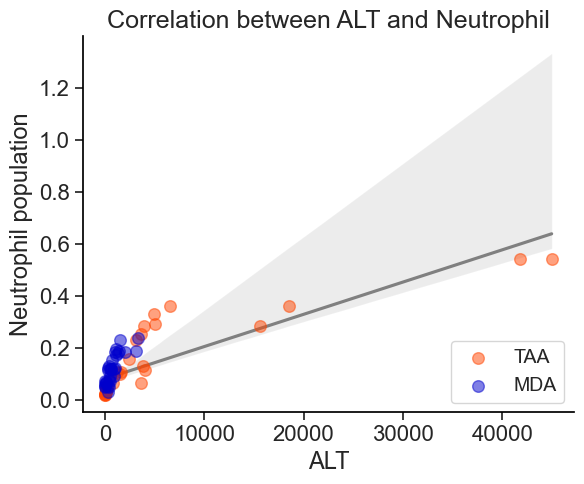

In [37]:
fig_name = "fig5b"+".png"
name = f"{root}/{fig_name}"
plot_alt_neu(df_total_v2, figname=name)

In [38]:
x = np.array(df_total_v2.loc[:, "ALT"])
y = np.array(df_total_v2.loc[:, "Neutrophil"])
print(np.corrcoef(x,y))
r = np.corrcoef(x,y)[0][1]
print('相関係数=',r)

[[1.         0.79584989]
 [0.79584989 1.        ]]
相関係数= 0.7958498874838151


## Fig.6 ##

#### (Fig.s3) ####

In [70]:
from sklearn.decomposition import PCA
from sklearn import manifold
from sklearn.manifold import TSNE
import umap.umap_ as umap
from sklearn import manifold

In [48]:
df = pd.read_csv("D:/Gdrive/notebook/2209_DrinkingWaterModel/221212_TAA_MDA/RNAseq/res_annotation.csv", index_col=0)
df_raw = pd.read_csv("D:/Gdrive/notebook/2209_DrinkingWaterModel/221212_TAA_MDA/rawdata/230528_DrinkingWaterModel_rawdata_v2.csv", index_col=0).iloc[:, 0:14]
clm_lst = [df_raw.iloc[i, 1]+"_"+str(df_raw.iloc[i, 2])+" mg/l_"+str(24*df_raw.iloc[i, 3])+" hr."+df_raw.iloc[i, 0] for i in range(len(df_raw)) if int(df_raw.iloc[i, 12]) != 1]
df.columns = clm_lst
df = df.T
df.head()

gene,0610005C13Rik,0610006L08Rik,0610009B22Rik,0610009E02Rik,0610009L18Rik,0610010K14Rik,0610012D04Rik,0610012G03Rik,0610025J13Rik,0610030E20Rik,...,n-R5s58,n-R5s60,n-R5s64,n-R5s65,n-R5s7,n-R5s71,n-R5s86,n-R5s88,n-R5s92,n-R5s93
Control_0 mg/l_24 hr.1C1,3770.065446,2.084791,391.177222,0.949394,15.736693,293.869352,0.0,439.145482,2.462917,152.112700,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Control_0 mg/l_24 hr.1C3,4410.865055,0.000000,537.198115,3.850322,19.152787,375.587333,0.0,453.919709,7.447075,295.274189,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Control_0 mg/l_24 hr.1C4,4272.064631,0.000000,579.246640,3.332056,19.228548,330.089108,0.0,466.205813,0.000000,272.087241,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Control_0 mg/l_48 hr.2C1,3342.789539,0.000000,555.810797,12.487572,26.073179,377.833964,0.0,371.002155,2.872635,253.252366,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Control_0 mg/l_48 hr.2C2,4330.943393,0.000000,569.437155,1.988059,19.636680,428.421320,0.0,394.494339,5.731423,294.324533,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [49]:
bacth_lst_comp = [df_raw.iloc[i, 1] for i in range(len(df_raw)) if int(df_raw.iloc[i, 12]) != 1]
batch_dict = zip(list(set(bacth_lst_comp)), ["Oranges", "Greys", "Blues"])
dct = {k: v for k, v in batch_dict}
batch_c_comp = [dct[i] for i in bacth_lst_comp]
day_lst = [float(df_raw.iloc[i, 3])/10 for i in range(len(df_raw)) if int(df_raw.iloc[i, 12]) != 1]
batch_c_comp_2 = [[dct[j], day_lst[i]] for i, j in enumerate(bacth_lst_comp)]

In [50]:
# Standardization
dfs = df.apply(lambda x: (x-x.mean())/x.std(), axis=0)
dfs_fix = dfs.dropna(axis=1)

In [51]:
pca = PCA()
pca.fit(dfs_fix)
feature = pca.transform(dfs_fix)

In [52]:
# 第一主成分と第二主成分でプロットする
def PCAplot(feature, bacth_lst_ex, batch_c_ex, xnum=0, ynum=1, title="RNAseq batch check", figname=None):
    fig, ax = plt.subplots()
    labelset = []
    ap = labelset.append
    for i in range(len(bacth_lst_ex)):
        if bacth_lst_ex[i] + " day" + str(10*batch_c_ex[i][1]) not in labelset:
            color_map = plt.get_cmap(batch_c_ex[i][0])
            ax.scatter(feature[:, xnum][i], feature[:, ynum][i], alpha=1, color=color_map((batch_c_ex[i][1])/2+0.4), label=bacth_lst_ex[i] + " day" + str(int(10*batch_c_ex[i][1])))
            ap(bacth_lst_ex[i] + " day" + str(10*batch_c_ex[i][1]))
        else:
            color_map = plt.get_cmap(batch_c_ex[i][0])
            ax.scatter(feature[:, xnum][i], feature[:, ynum][i], alpha=1, color=color_map((batch_c_ex[i][1])/2+0.4), label="")
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    ax.set_title(title, fontsize=18)
    ax.set_xlabel("PC"+str(xnum+1), fontsize=15)
    ax.set_ylabel("PC"+str(ynum+1), fontsize=15)

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    if figname:
        plt.savefig(figname, dpi=300)
    plt.show()

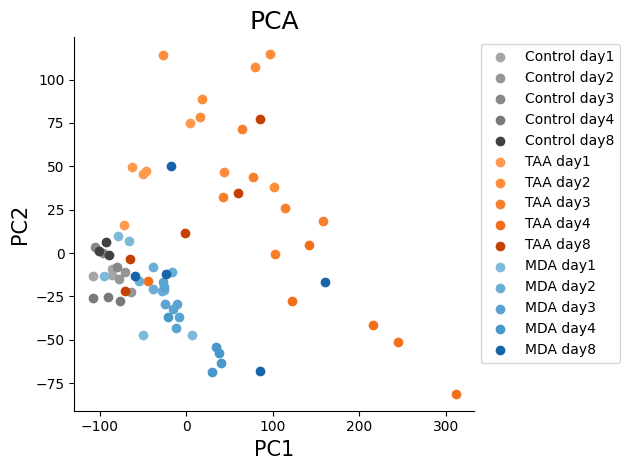

In [56]:
PCAplot(feature, bacth_lst_comp, batch_c_comp_2, xnum=0, ynum=1, title="PCA", figname=f"{root}/figs3a1")

In [57]:
df_target = np.log2(df+1)
#標準化
dfs = df_target .apply(lambda x: (x-x.mean())/x.std(), axis=0)

print("len(dfs) = ", len(dfs.T))
dfs_fix = dfs.dropna(how='all', axis=1)
print("len(dfs_fix) = ", len(dfs_fix.T))

len(dfs) =  54154
len(dfs_fix) =  31611


In [58]:
pca = PCA()
pca.fit(dfs_fix)
feature_log = pca.transform(dfs_fix)

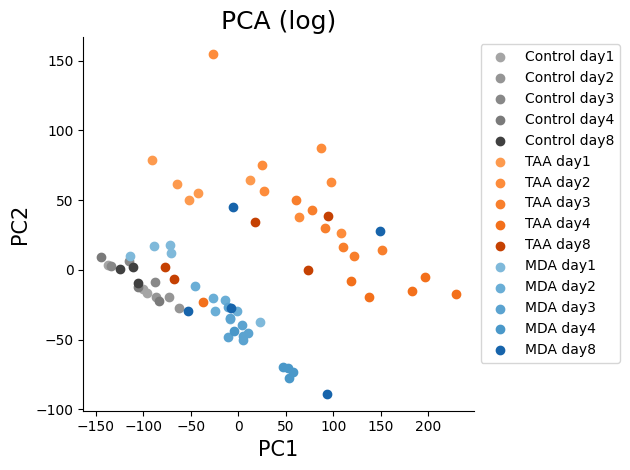

In [59]:
PCAplot(feature_log, bacth_lst_comp, batch_c_comp_2, xnum=0, ynum=1, title="PCA (log)", figname=f"{root}/figs3a2")

In [60]:
# 第一主成分と第二主成分でプロットする
def tSNEplot(feature, bacth_lst_ex, batch_c_ex, xnum=0, ynum=1, title="RNAseq batch check", figname=None):
    fig, ax = plt.subplots()
    labelset = []
    ap = labelset.append
    for i in range(len(bacth_lst_ex)):
        if bacth_lst_ex[i] + " day" + str(10*batch_c_ex[i][1]) not in labelset:
            color_map = plt.get_cmap(batch_c_ex[i][0])
            ax.scatter(feature[xnum][i], feature[ynum][i], alpha=1, color=color_map((batch_c_ex[i][1])/2+0.4), label=bacth_lst_ex[i] + " day" + str(int(10*batch_c_ex[i][1])))
            ap(bacth_lst_ex[i] + " day" + str(10*batch_c_ex[i][1]))
        else:
            color_map = plt.get_cmap(batch_c_ex[i][0])
            ax.scatter(feature[xnum][i], feature[ynum][i], alpha=1, color=color_map((batch_c_ex[i][1])/2+0.4), label="")
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    ax.set_title(title, fontsize=18)
    ax.set_xlabel("axis"+str(xnum+1), fontsize=15)
    ax.set_ylabel("axis"+str(ynum+1), fontsize=15)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    if figname:
        plt.savefig(figname, dpi=300)
    plt.show()

In [63]:
model =  manifold.MDS(n_components=2, max_iter=300, n_init=4, random_state=24771) # max_iter, n_initは初期値
x_embedded_mds = model.fit_transform(dfs_fix.values)
feature = [[i[0] for i in x_embedded_mds], [i[1]for i in x_embedded_mds]]

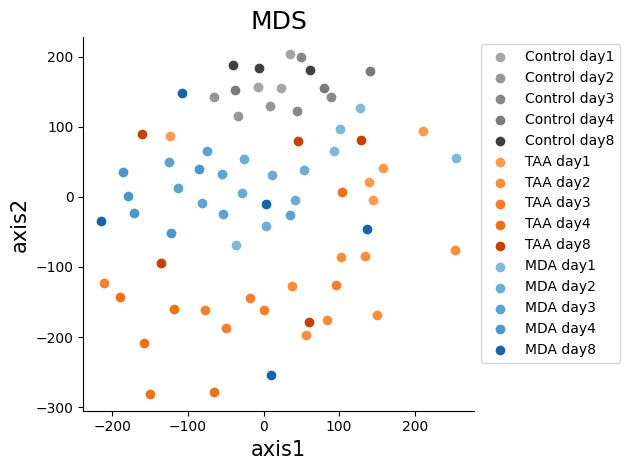

In [64]:
tSNEplot(feature, bacth_lst_comp, batch_c_comp_2, xnum=0, ynum=1, title="MDS", figname=f"{root}/figs3b.png")

c:\Users\2022_iwasaka\miniconda3\envs\standerd\lib\site-packages\sklearn\manifold\_t_sne.py:800: FutureWarning: The default initialization in TSNE will change from 'random' to 'pca' in 1.2.
  warnings.warn(
c:\Users\2022_iwasaka\miniconda3\envs\standerd\lib\site-packages\sklearn\manifold\_t_sne.py:810: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  warnings.warn(


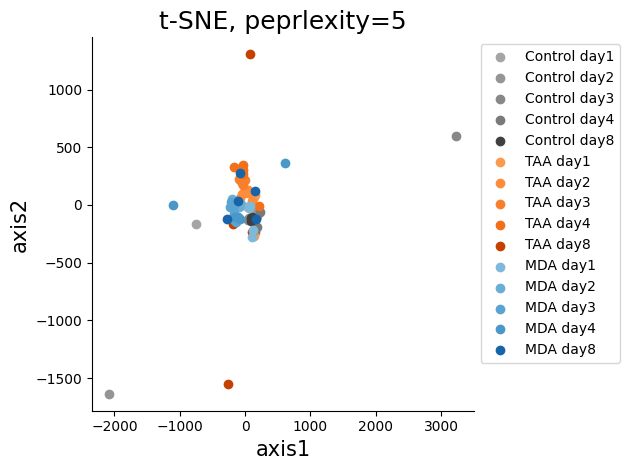

c:\Users\2022_iwasaka\miniconda3\envs\standerd\lib\site-packages\sklearn\manifold\_t_sne.py:800: FutureWarning: The default initialization in TSNE will change from 'random' to 'pca' in 1.2.
  warnings.warn(
c:\Users\2022_iwasaka\miniconda3\envs\standerd\lib\site-packages\sklearn\manifold\_t_sne.py:810: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  warnings.warn(


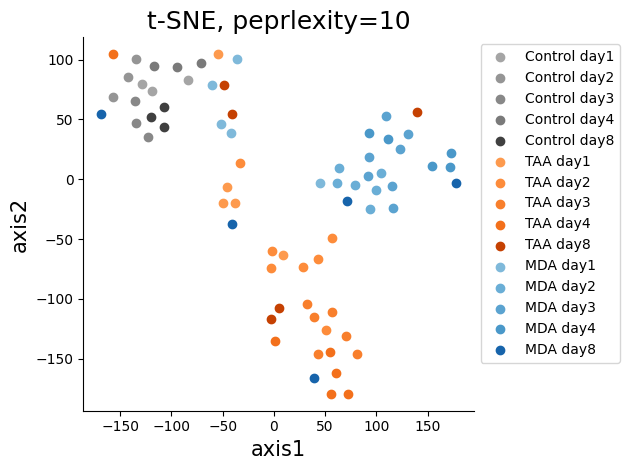

c:\Users\2022_iwasaka\miniconda3\envs\standerd\lib\site-packages\sklearn\manifold\_t_sne.py:800: FutureWarning: The default initialization in TSNE will change from 'random' to 'pca' in 1.2.
  warnings.warn(
c:\Users\2022_iwasaka\miniconda3\envs\standerd\lib\site-packages\sklearn\manifold\_t_sne.py:810: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  warnings.warn(


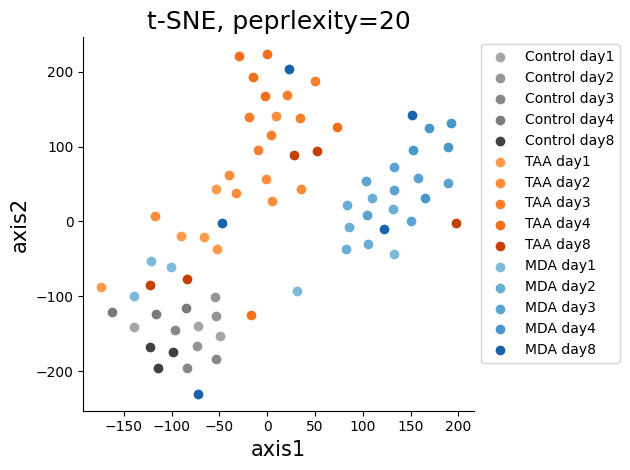

c:\Users\2022_iwasaka\miniconda3\envs\standerd\lib\site-packages\sklearn\manifold\_t_sne.py:800: FutureWarning: The default initialization in TSNE will change from 'random' to 'pca' in 1.2.
  warnings.warn(
c:\Users\2022_iwasaka\miniconda3\envs\standerd\lib\site-packages\sklearn\manifold\_t_sne.py:810: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  warnings.warn(


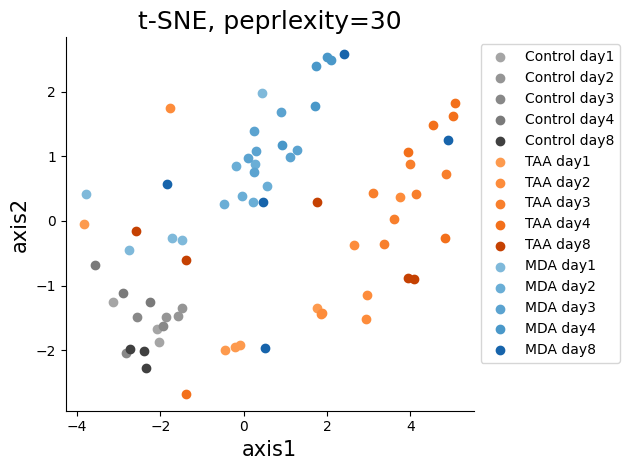

In [69]:
for n, i in enumerate([5, 10, 20, 30]):
    fig_name = "figs3c"+str(n+1)+".png"
    name = f"{root}/{fig_name}"
    model_tsne = TSNE(n_components=2, perplexity=i, random_state=24771)
    tsne_feature = model_tsne.fit_transform(dfs_fix)
    feature = [[i[0] for i in tsne_feature], [i[1]for i in tsne_feature]]
    tSNEplot(feature, bacth_lst_comp, batch_c_comp_2, xnum=0, ynum=1, title="t-SNE, peprlexity="+str(i), figname=name)

In [67]:
# 第一主成分と第二主成分でプロットする
def UMAPplot(feature, bacth_lst_ex, batch_c_ex, xnum=0, ynum=1, title="RNAseq batch check", figname=None):
    fig, ax = plt.subplots()
    labelset = []
    ap = labelset.append
    for i in range(len(bacth_lst_ex)):
        if bacth_lst_ex[i] + " day" + str(10*batch_c_ex[i][1]) not in labelset:
            color_map = plt.get_cmap(batch_c_ex[i][0])
            ax.scatter(feature[xnum][i], feature[ynum][i], alpha=1, color=color_map((batch_c_ex[i][1])/2+0.4), label=bacth_lst_ex[i] + " day" + str(int(10*batch_c_ex[i][1])))
            ap(bacth_lst_ex[i] + " day" + str(10*batch_c_ex[i][1]))
        else:
            color_map = plt.get_cmap(batch_c_ex[i][0])
            ax.scatter(feature[xnum][i], feature[ynum][i], alpha=1, color=color_map((batch_c_ex[i][1])/2+0.4), label="")
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    ax.set_title(title, fontsize=18)
    ax.set_xlabel("axis"+str(xnum+1), fontsize=15)
    ax.set_ylabel("axis"+str(ynum+1), fontsize=15)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    if figname:
        plt.savefig(figname, dpi=300)
    plt.show()

C:\Users\2022_iwasaka\AppData\Roaming\Python\Python310\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


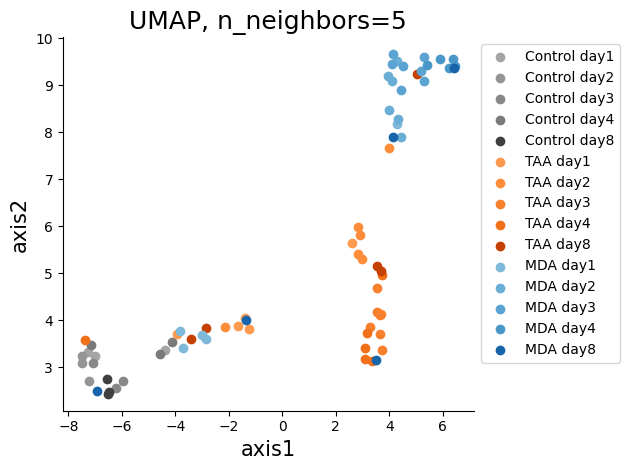

C:\Users\2022_iwasaka\AppData\Roaming\Python\Python310\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


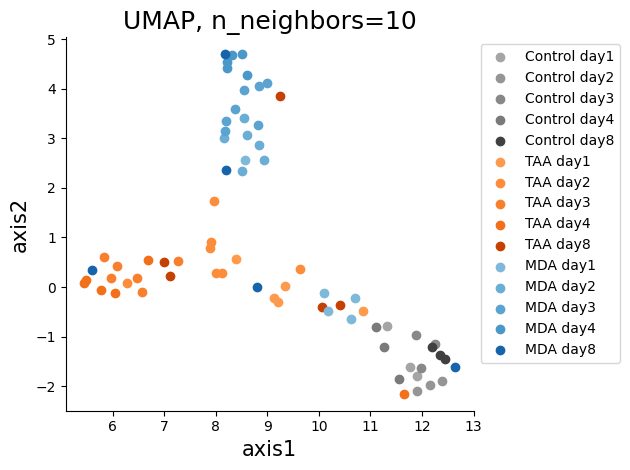

C:\Users\2022_iwasaka\AppData\Roaming\Python\Python310\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


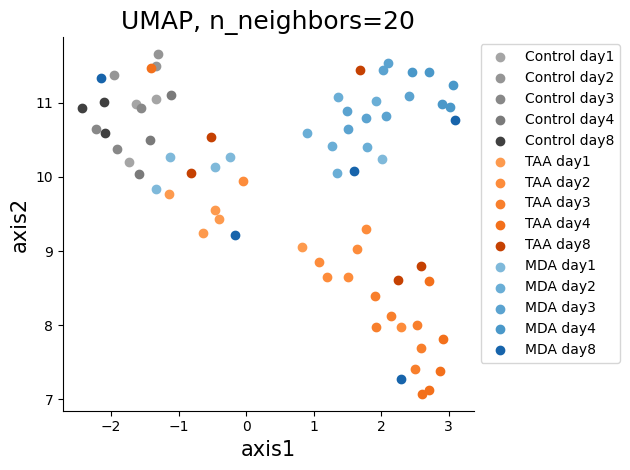

C:\Users\2022_iwasaka\AppData\Roaming\Python\Python310\site-packages\umap\umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


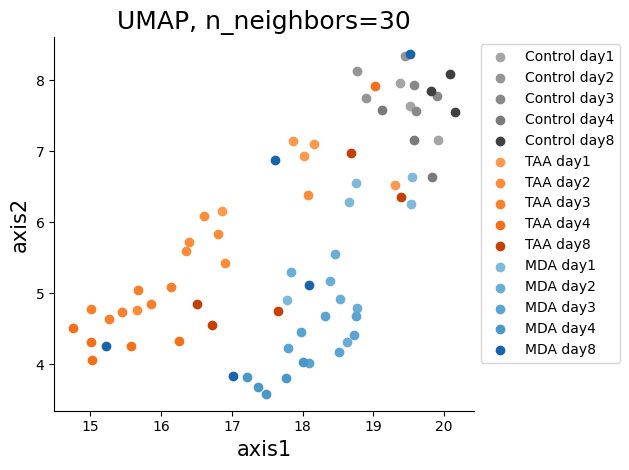

In [68]:
for n, i in enumerate([5, 10, 20, 30]):
    fig_name = "figs3d"+str(n+1)+".png"
    name = f"{root}/{fig_name}"
    model_umap = umap.UMAP(n_components=2, random_state=24771, n_neighbors=i)
    umap_feature = model_umap.fit_transform(dfs_fix)
    feature = [[i[0] for i in umap_feature], [i[1]for i in umap_feature]]
    UMAPplot(feature, bacth_lst_comp, batch_c_comp_2, xnum=0, ynum=1, title="UMAP, n_neighbors="+str(i), figname=name)

In [71]:
model = manifold.SpectralEmbedding(n_components=2, n_neighbors=20, random_state=24771)
x_embedded_spc = model.fit_transform(dfs_fix.values)
feature = [[i[0] for i in x_embedded_spc], [i[1]for i in x_embedded_spc]]

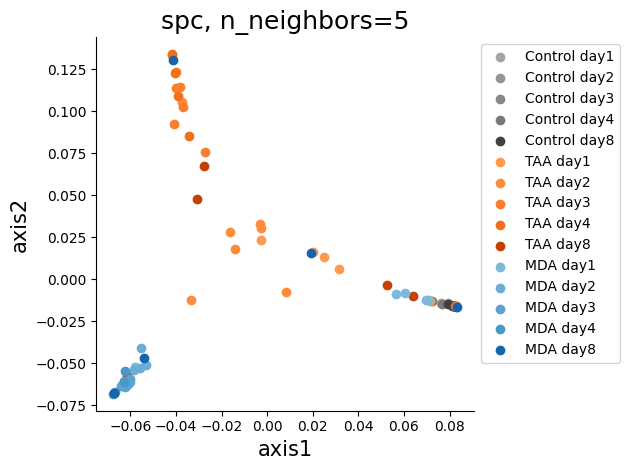

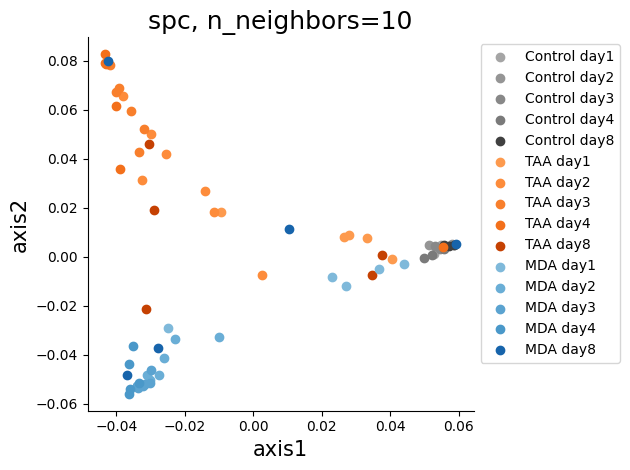

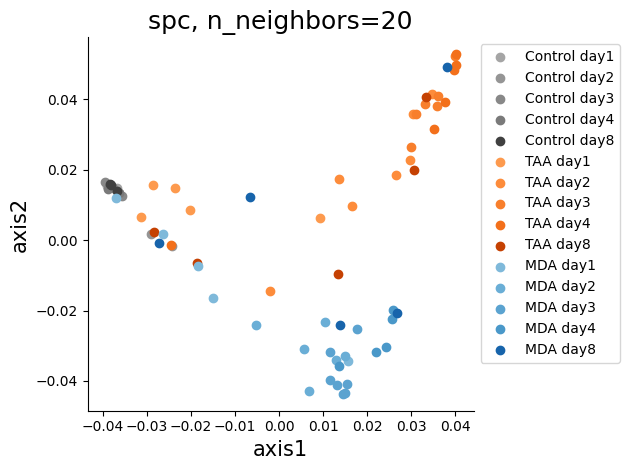

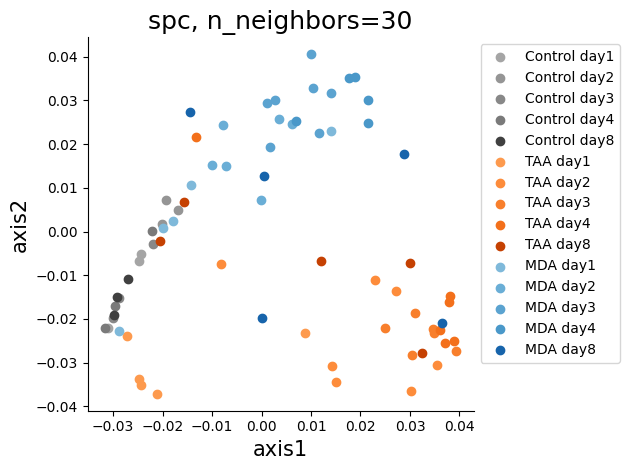

In [72]:
for n, i in enumerate([5, 10, 20, 30]):
    fig_name = "figs3e"+str(n+1)+".png"
    name = f"{root}/{fig_name}"
    model = manifold.SpectralEmbedding(n_components=2, n_neighbors=i, random_state=24771)
    x_embedded_spc = model.fit_transform(dfs_fix.values)
    feature = [[i[0] for i in x_embedded_spc], [i[1]for i in x_embedded_spc]]
    UMAPplot(feature, bacth_lst_comp, batch_c_comp_2, xnum=0, ynum=1, title="spc, n_neighbors="+str(i), figname=name)

In [73]:
model = manifold.LocallyLinearEmbedding(method="standard", random_state=24771)
x_embedded_lle=model.fit_transform(dfs_fix.values)
feature = [[i[0] for i in x_embedded_lle], [i[1]for i in x_embedded_lle]]

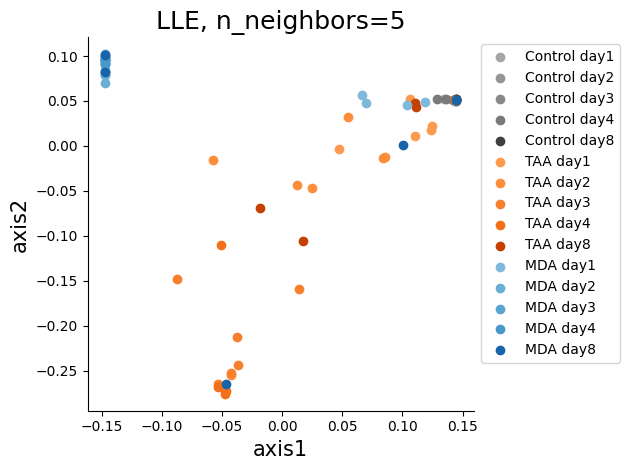

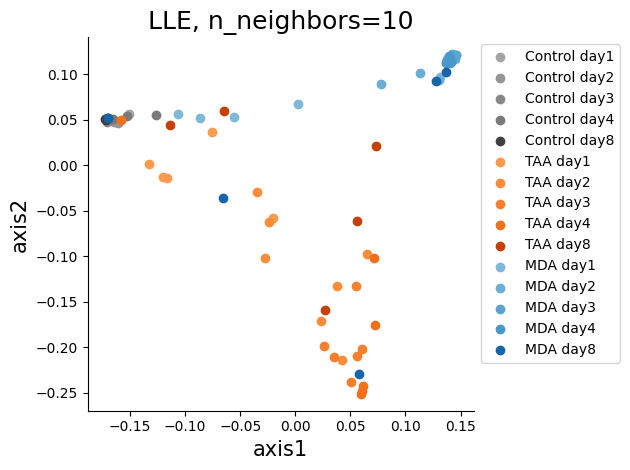

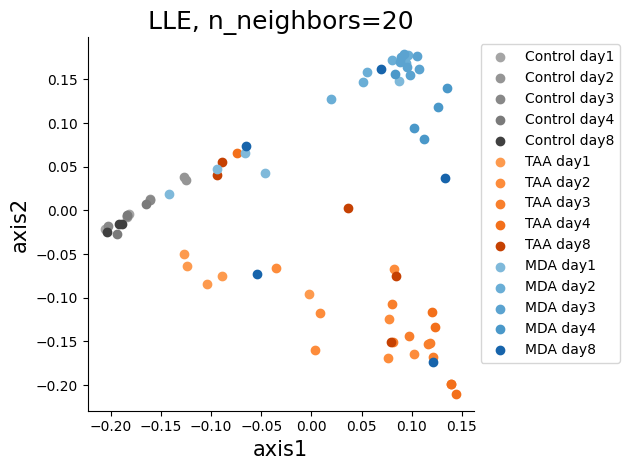

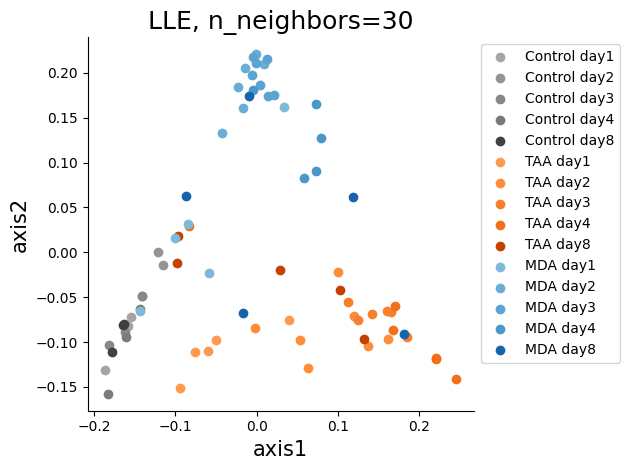

In [74]:
for n, i in enumerate([5, 10, 20, 30]):
    fig_name = "figs3f"+str(n+1)+".png"
    name = f"{root}/{fig_name}"
    model = manifold.LocallyLinearEmbedding(method="standard", n_neighbors=i, random_state=24771)
    x_embedded_lle=model.fit_transform(dfs_fix.values)
    feature = [[i[0] for i in x_embedded_lle], [i[1]for i in x_embedded_lle]]
    UMAPplot(feature, bacth_lst_comp, batch_c_comp_2, xnum=0, ynum=1, title="LLE, n_neighbors="+str(i), figname=name)

### (a, b) META Visualization ###

In [76]:
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.decomposition import PCA
from sklearn import manifold

import umap.umap_ as umap

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams["font.size"] = 18
warnings.simplefilter('ignore')

In [77]:
df = pd.read_csv("D:/Gdrive/notebook/2209_DrinkingWaterModel/221212_TAA_MDA/RNAseq/res_annotation.csv", index_col=0)
df_raw = pd.read_csv("D:/Gdrive/notebook/2209_DrinkingWaterModel/221212_TAA_MDA/rawdata/230528_DrinkingWaterModel_rawdata_v2.csv", index_col=0).iloc[:, 0:14]
clm_lst = [df_raw.iloc[i, 1]+"_"+str(df_raw.iloc[i, 2])+" mg/l_"+str(24*df_raw.iloc[i, 3])+" hr."+df_raw.iloc[i, 0] for i in range(len(df_raw)) if int(df_raw.iloc[i, 12]) != 1]
df.columns = clm_lst
df = df.T
df.head()

gene,0610005C13Rik,0610006L08Rik,0610009B22Rik,0610009E02Rik,0610009L18Rik,0610010K14Rik,0610012D04Rik,0610012G03Rik,0610025J13Rik,0610030E20Rik,...,n-R5s58,n-R5s60,n-R5s64,n-R5s65,n-R5s7,n-R5s71,n-R5s86,n-R5s88,n-R5s92,n-R5s93
Control_0 mg/l_24 hr.1C1,3770.065446,2.084791,391.177222,0.949394,15.736693,293.869352,0.0,439.145482,2.462917,152.112700,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Control_0 mg/l_24 hr.1C3,4410.865055,0.000000,537.198115,3.850322,19.152787,375.587333,0.0,453.919709,7.447075,295.274189,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Control_0 mg/l_24 hr.1C4,4272.064631,0.000000,579.246640,3.332056,19.228548,330.089108,0.0,466.205813,0.000000,272.087241,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Control_0 mg/l_48 hr.2C1,3342.789539,0.000000,555.810797,12.487572,26.073179,377.833964,0.0,371.002155,2.872635,253.252366,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Control_0 mg/l_48 hr.2C2,4330.943393,0.000000,569.437155,1.988059,19.636680,428.421320,0.0,394.494339,5.731423,294.324533,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [78]:
df_target = np.log2(df+1)
#標準化
dfs = df_target .apply(lambda x: (x-x.mean())/x.std(), axis=0)

print("len(dfs) = ", len(dfs.T))
dfs_fix = dfs.dropna(how='all', axis=1)
print("len(dfs_fix) = ", len(dfs_fix.T))

len(dfs) =  54154
len(dfs_fix) =  31611


In [79]:
def meta_viz(visualizations, projection_method=None):
    '''
    Inputs:
       visualizations [list of numpy arrays]
        - list of numpy arrays of size n x 2 (columns being the two-dimensional coordinates of visualization)
        - each row should be matched to the same observation/sample across all elements in the list
       projection_method [str or None]
        - options are "tSNE" or "MDS" for reprojecting the meta-distance matrix into a meta-visualization

    Approach:
        1. Computes euclidean distance matrices from 2D embeddings
        2. Ensembles the euclidean distance according to eigenvector with largest eigenvalue
        3. Uses projection_method ["MDS", "tSNE"] to transform euclidean distance matrix to 2D embeddings

    Returns:
        meta_visualization [numpy array] - size nx2 two-dimensional visualization genereated using the meta-visualization approach
            - returned only if projection_method is not None
        meta_distances [numpy array] - size nxn pairwise euclidean distance matrix generated using meta-visualization approach
    '''
    # define number of samples
    n = visualizations[0].shape[0]
    K = len(visualizations)

    # Iterate and record distance matrices
    X_distance_matrix_list = []

    # compute pairwise distance matrix
    for X_embedded in visualizations:
        assert X_embedded.shape[0] == n, "All visualization arrays need to have the same number of rows"
        assert X_embedded.shape[1] == 2, "All visualization arrays need to have two columns"
        X_distance = metrics.pairwise_distances(X_embedded)
        X_distance_matrix_list.append(X_distance)

    # Compute weights for meta-visualization
    meta_distances = np.zeros((n,n))
    weights = np.zeros((n,K))
    for j in range(n):
        # fill in comparison matrix
        comp_mat = np.zeros((K,K))
        for i in range(K):
            for k in range(K):
                comp_mat[i,k] = np.sum(X_distance_matrix_list[k][:,j]*X_distance_matrix_list[i][:,j])/np.sqrt(np.sum(X_distance_matrix_list[k][:,j]**2))/np.sqrt(np.sum(X_distance_matrix_list[i][:,j]**2))
        # Eigenscore
        w, v = np.linalg.eig(comp_mat)
        weights[j,:] = np.abs(v[:,0])

        # Ensembles distance matrices
        matrix_norms = []
        for i in range(K):
            matrix_norms.append(X_distance_matrix_list[i][:,j]/np.sqrt(np.sum(X_distance_matrix_list[i][:,j]**2)))

        temp = np.zeros(matrix_norms[0].shape)
        for i in range(K):
            temp += matrix_norms[i]*weights[j,i]

        meta_distances[:,j] = temp

    meta_distances = np.nan_to_num((meta_distances+meta_distances.T)/2)

    # Re-project on 2D embedding space
    if projection_method is None:
        return(meta_distances)
    else:
        if projection_method == "tSNE":
            tsne = manifold.TSNE(n_components=2, metric="precomputed", verbose=0).fit(meta_distances)
            meta_visualization = tsne.embedding_
        elif projection_method == "MDS":
            mds = manifold.MDS(n_components=2, verbose=0, dissimilarity="precomputed").fit(meta_distances)
            meta_visualization = mds.embedding_

        return(meta_visualization, meta_distances)

In [80]:
def meta_viz_calc(df, random_state=24771):
    model = manifold.LocallyLinearEmbedding(method="standard", n_neighbors=20, random_state=random_state) #231106 n_neighbors=5 (default) → 20
    x_embedded_lle=model.fit_transform(df.values)
    model =  manifold.MDS(n_components=2, max_iter=300, n_init=4, random_state=random_state) #231011 max_iter=50 → 300
    x_embedded_mds = model.fit_transform(df.values)
    model = manifold.SpectralEmbedding(n_components=2, n_neighbors=20, random_state=random_state)
    x_embedded_spc = model.fit_transform(df.values)
    model = PCA(n_components=2, random_state=random_state)
    x_embedded_pca = model.fit_transform(df.values)
    model = manifold.TSNE(n_components=2, perplexity=10, random_state=random_state)
    x_embedded_tsne = model.fit_transform(df.values)
    model = umap.UMAP(n_components=2, random_state=random_state, n_neighbors=10)
    x_embedded_umap = model.fit_transform(df.values)
    meta_visualization, meta_distances = meta_viz([x_embedded_lle, x_embedded_mds, x_embedded_spc, x_embedded_pca, x_embedded_tsne, x_embedded_umap], projection_method="MDS")
    return meta_visualization, meta_distances

In [81]:
meta_visualization, meta_distances = meta_viz_calc(dfs_fix)

In [82]:
# 第一主成分と第二主成分でプロットする
def METAplot(feature, bacth_lst_ex, batch_c_ex, xnum=0, ynum=1, title="META Visualization", figname=None):
    fig = plt.figure(figsize=(10,7))
    ax=fig.add_subplot(111)
    labelset = []
    ap = labelset.append
    for i in range(len(bacth_lst_ex)):
        if bacth_lst_ex[i] + " day" + str(10*batch_c_ex[i][1]) not in labelset:
            color_map = plt.get_cmap(batch_c_ex[i][0])
            ax.scatter(feature[xnum][i], feature[ynum][i], alpha=1, s=70, color="w", linewidth=3, ec=color_map((batch_c_ex[i][1])/2+0.4), label=bacth_lst_ex[i] + " day" + str(int(10*batch_c_ex[i][1])))
            ap(bacth_lst_ex[i] + " day" + str(10*batch_c_ex[i][1]))
        else:
            color_map = plt.get_cmap(batch_c_ex[i][0])
            ax.scatter(feature[xnum][i], feature[ynum][i], alpha=1, s=70, color="w", linewidth=3, ec=color_map((batch_c_ex[i][1])/2+0.4), label="")
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1), ncol=1)
    ax.set_title(title, fontsize=24)
    ax.set_xlabel("Component "+str(xnum+1), fontsize=20)
    ax.set_ylabel("Component "+str(ynum+1), fontsize=20)

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    if figname:
        plt.savefig(figname, dpi=300)
    plt.show()

In [86]:
bacth_lst_comp = [df_raw.iloc[i, 1] for i in range(len(df_raw)) if int(df_raw.iloc[i, 12]) != 1]
batch_dict = zip(list(set(bacth_lst_comp)), ["Oranges", "Greys", "Blues"])
dct = {k: v for k, v in batch_dict}
batch_c_comp = [dct[i] for i in bacth_lst_comp]
day_lst = [float(df_raw.iloc[i, 3])/10 for i in range(len(df_raw)) if int(df_raw.iloc[i, 12]) != 1]
batch_c_comp_2 = [[dct[j], day_lst[i]] for i, j in enumerate(bacth_lst_comp)]

In [87]:
feature_meta = [[meta_visualization[i][0] for i in range(len(meta_visualization))], [meta_visualization[i][1] for i in range(len(meta_visualization))]]

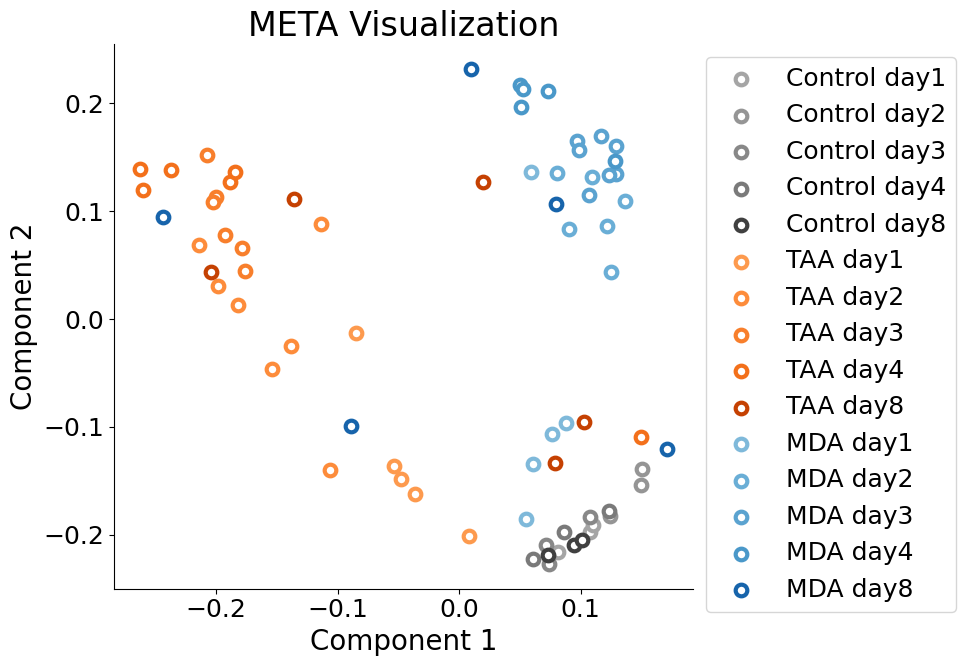

In [88]:
METAplot(feature_meta, bacth_lst_comp, batch_c_comp_2, xnum=0, ynum=1, figname=f"{root}/fig6a.png")

In [89]:
alt_lst = [float(df_raw.iloc[i, 5]) for i in range(len(df_raw)) if int(df_raw.iloc[i, 12]) != 1]
batch_c_comp_3 = [["jet", day_lst[i], alt_lst[i]] for i in range(len(bacth_lst_comp))]

In [94]:
# 第一主成分と第二主成分でプロットする
def METAplot2(feature, bacth_lst_ex, batch_c_ex, xnum=0, ynum=1, title="META Visualization", figname=None):
    fig = plt.figure(figsize=(9,7))
    ax=fig.add_subplot(111)
    labelset = []
    ap = labelset.append
    for i in range(len(bacth_lst_ex)):
        if bacth_lst_ex[i] + " day" + str(10*batch_c_ex[i][1]) not in labelset:
            color_map = plt.get_cmap(batch_c_ex[i][0])
            ax.scatter(feature[xnum][i], feature[ynum][i], alpha=1, s=70, color="w", linewidth=3, ec=color_map((batch_c_ex[i][2])/1000), label=bacth_lst_ex[i] + " day" + str(int(10*batch_c_ex[i][1])))
            ap(bacth_lst_ex[i] + " day" + str(10*batch_c_ex[i][1]))
        else:
            color_map = plt.get_cmap(batch_c_ex[i][0])
            ax.scatter(feature[xnum][i], feature[ynum][i], alpha=1, s=70, color="w", linewidth=3, ec=color_map((batch_c_ex[i][2])/1000), label="")


    a=[-10,-20]
    b=[-10,-20]
    c=[0,1000]
    img = plt.scatter(a,b,c=c,cmap=plt.get_cmap(batch_c_ex[0][0]),alpha=1)
    plt.colorbar(img)

    #ax.legend(loc='upper left', bbox_to_anchor=(1, 1), ncol=1)
    ax.set_title(title, fontsize=24)
    ax.set_xlabel("Component "+str(xnum+1), fontsize=20)
    ax.set_ylabel("Component "+str(ynum+1), fontsize=20)

    #ax.set_xlim(-130,410)

    ax.grid(False)
    [ax.spines[side].set_visible(False) for side in ['right','top']]

    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    plt.xlim(-0.29,0.199)
    plt.ylim(-0.26,0.26)

    plt.tick_params(bottom=True, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    if figname:
        plt.savefig(figname, dpi=300)
    plt.show()

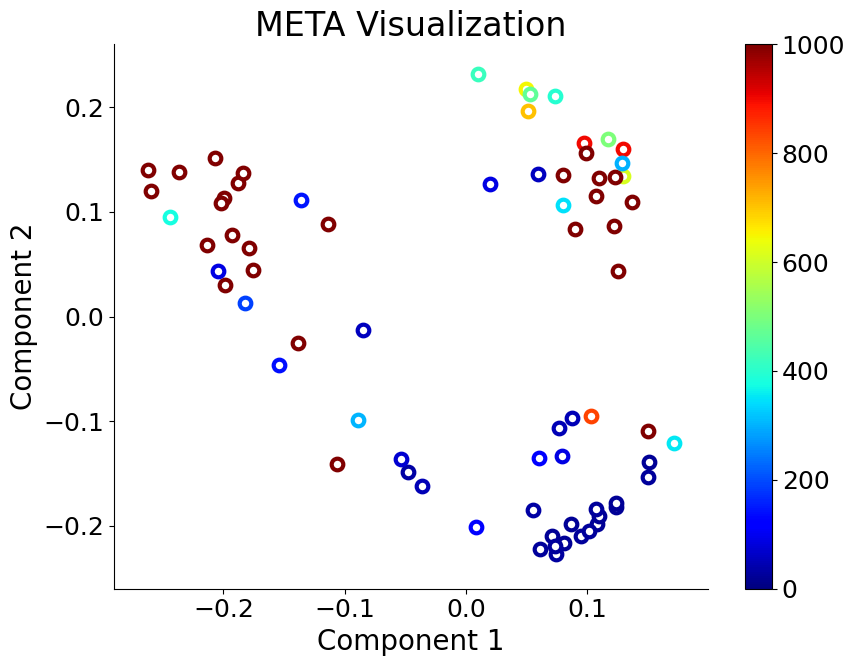

In [95]:
METAplot2(feature_meta, bacth_lst_comp, batch_c_comp_3, xnum=0, ynum=1, figname=f"{root}/fig6b.png")

## Fig.7 ##

### (a, b) GAGE ###

In [111]:
from sklearn.impute import KNNImputer
from scipy import stats
from statutil.multivariate_test import t_integration as ting

import pickle
from statutil.single_test import rankproduct as rp
import math

In [113]:
df = pd.read_csv("D:/Gdrive/notebook/2209_DrinkingWaterModel/221212_TAA_MDA/RNAseq/res_annotation.csv", index_col=0)
df_raw = pd.read_csv("D:/Gdrive/notebook/2209_DrinkingWaterModel/221212_TAA_MDA/rawdata/230528_DrinkingWaterModel_rawdata_v2.csv", index_col=0).iloc[:, 0:14]

# 小文字への変換
ind_lst = [i.lower() for i in df.index.tolist()]
clm_lst = [(df_raw.iloc[i, 1]+"_"+str(df_raw.iloc[i, 2])+" mg/l_"+str(24*df_raw.iloc[i, 3])+" hr."+df_raw.iloc[i, 0]).lower() for i in range(len(df_raw)) if int(df_raw.iloc[i, 12]) != 1]
df.index = ind_lst
df.columns = clm_lst
ref = pd.read_pickle("D:/Gdrive/notebook/2209_DrinkingWaterModel/221212_TAA_MDA\RNAseq/ssGSEA_GO/go_mouse_msigdb.pickle")
for i in ref.keys():
    ref[i] = {j.lower() for j in ref[i]}

In [114]:
gene_lst = []
apgene = gene_lst.append
for geneset in list(ref.values()):
    for gene in geneset:
        apgene(gene)
gene_set = set(gene_lst)
gene_lst = list(gene_set)
print("total gene count (from go_mouse_msigdb):", len(gene_lst))
print("total gene count (from rnaseq data):", len(df.index.tolist()))

overlap_gene_lst = list(set(df.index.tolist()) & gene_set)
print("overlap gene count :", len(overlap_gene_lst ))

total gene count (from go_mouse_msigdb): 19861
total gene count (from rnaseq data): 54154
overlap gene count : 19816


In [115]:
df_target = df.loc[overlap_gene_lst, :]
df_log = np.log2(df_target+1)

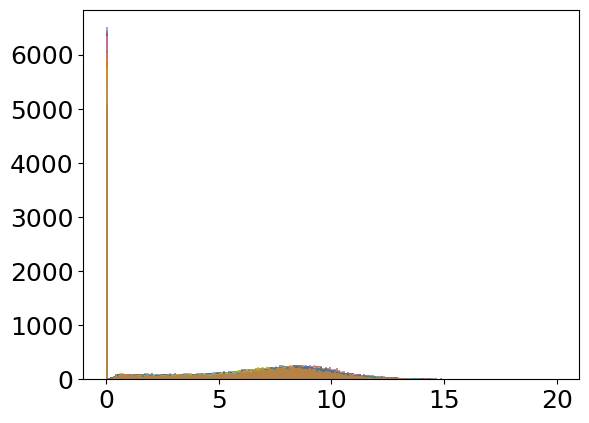

In [116]:
# Confirm distribution

for i in range(72):
    plt.hist(df_log.iloc[:,i],bins=200,alpha=0.65, range=(0, 20)) # Insert numbers as you see fit
plt.show()

In [118]:
def low_exp_cut_v4(df, threshold=np.log2(10), count_thresh=3):
    imputer = KNNImputer()
    df_log = np.log2(df+1)
    print("gene count (before processing):" + str(len(df_log)))
    df_log = df_log[df_log>threshold].fillna(float(0)) #threshold以下の値を0に統一
    df_target = df_log[df_log>0].fillna(np.NaN) #0をNanに

    # gene selection part
    col_lst = df.columns.tolist()
    print("Number of samples:", len(col_lst))
    df_test = df_target.isnull().sum(axis=1) #遺伝子ごとのNan数の合計を算出
    gene_lst = [ind for ind in df_test.index.tolist() if df_test[ind] > len(col_lst)-count_thresh and df_test[ind] < len(col_lst)] #Nanではない値の数がcount_thresh以下の遺伝子のlistを取得

    up_gene_lst = []
    ap = up_gene_lst.append

    n = len(gene_lst)
    print("Number of genes to be tested:", n)

    for gene in gene_lst:
        fvalue, pvalue = stats.f_oneway(
            df_log.loc[gene, df_log.columns.str.contains("control")], 
            df_log.loc[gene, df_log.columns.str.contains("taa_300 mg/l_24 hr")], 
            df_log.loc[gene, df_log.columns.str.contains("taa_300 mg/l_48 hr")], 
            df_log.loc[gene, df_log.columns.str.contains("taa_300 mg/l_72 hr")], 
            df_log.loc[gene, df_log.columns.str.contains("taa_300 mg/l_96 hr")], 
            df_log.loc[gene, df_log.columns.str.contains("taa_300 mg/l_192 hr")], 
            df_log.loc[gene, df_log.columns.str.contains("mda_750 mg/l_24 hr")], 
            df_log.loc[gene, df_log.columns.str.contains("mda_750 mg/l_48 hr")], 
            df_log.loc[gene, df_log.columns.str.contains("mda_750 mg/l_72 hr")], 
            df_log.loc[gene, df_log.columns.str.contains("mda_750 mg/l_96 hr")], 
            df_log.loc[gene, df_log.columns.str.contains("mda_750 mg/l_192 hr")])
        if pvalue <= 0.05/n:
            #print("up-regulated gene : ", gene)
            ap(gene)
    print("gene count (up-regulated gene):", len(up_gene_lst)) #取得した遺伝子の数
    
    df_log_up_reg = df_log.loc[up_gene_lst, :] #発現上昇 (or 減少)を強調するため0のままのdfを残しておく
    
    df_target = df_target.dropna(thresh=count_thresh) #Nanの数がcount_threshを超えるものは遺伝子そのものを排除
    print("gene count (after dropna):" + str(len(df_target)))

    df_target = pd.DataFrame(imputer.fit_transform(df_target), index=df_target.index.tolist(), columns=df_target.columns.tolist()) #KNN imputerで欠損値の補完

    df_target4 = pd.concat([df_target, df_log_up_reg], axis=0) #事前取得しておいたup-regulated geneをもとに戻す
    print("gene count (after all processing):" + str(len(df_target4)))

    return up_gene_lst, df_target4

In [119]:
up_gene_lst, df_target4 = low_exp_cut_v4(df_target, threshold=np.log2(1), count_thresh=50) 

gene count (before processing):19816
Number of samples: 72
Number of genes to be tested: 3543
gene count (up-regulated gene): 246
gene count (after dropna):13424
gene count (after all processing):13670


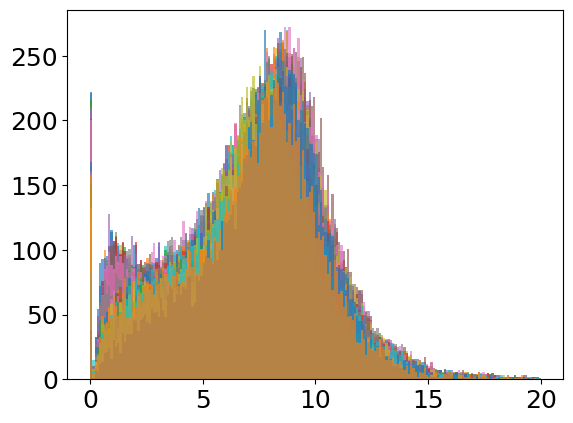

In [120]:
# Confirm distribution

for i in range(72):
    plt.hist(df_target4.iloc[:,i],bins=200,alpha=0.65, range=(0, 20)) # Insert numbers as you see fit
plt.show()

In [121]:
ref = pd.read_pickle("D:/Gdrive/notebook/2209_DrinkingWaterModel/221212_TAA_MDA\RNAseq/ssGSEA_GO/go_mouse_msigdb.pickle")
for i in ref.keys():
    ref[i] = {j.lower() for j in ref[i]}

In [122]:
gene_lst = df_target4.index.tolist()

In [123]:
ratio = 0
num = 15
print("go count (before processing): " + str(len(ref)))
n = 0
for i in list(ref.keys()):
    if len(ref[i] & set(gene_lst)) <= num:
        n += 1
        del ref[i]
    elif len(ref[i] & set(gene_lst)) < ratio*len(ref[i]):
        print(ref[i])
        n += 1
        del ref[i]
print("go count (After processing): " + str(len(ref)))
print("go count (del): " + str(n))

go count (before processing): 10673
go count (After processing): 5207
go count (del): 5466


In [124]:
res_lst_v4 = []
ap = res_lst_v4.append
target_lst = list(set([i.split(".")[0] for i in df_target4.columns.tolist() if i.split("_")[0] != "control"]))
for group in target_lst:
    res = ting.calc(
    data=df_target4,
    treatment=group,
    control="control",
    group=ref,
    sign=True,
    )
    ls = [res, group]
    ap(ls)
    print(group + " end")

mda_750 mg/l_72 hr end
mda_750 mg/l_24 hr end
mda_750 mg/l_96 hr end
taa_300 mg/l_192 hr end
taa_300 mg/l_96 hr end
taa_300 mg/l_48 hr end
taa_300 mg/l_24 hr end
mda_750 mg/l_192 hr end
mda_750 mg/l_48 hr end
taa_300 mg/l_72 hr end


In [127]:
df_gage_raw = res_lst_v4[1][0]
df_gage_raw["ID"] = [res_lst_v4[1][1]]*len(df_gage_raw)

In [129]:
gage_rawdata = pd.DataFrame()

for lst in res_lst_v4:
    df_gage_raw = lst[0]
    df_gage_raw["ID"] = [lst[1]]*len(df_gage_raw)
    gage_rawdata = pd.concat([gage_rawdata, df_gage_raw])

In [131]:
gage_rawdata.columns = ["p_val", "adjusted_p_val", "corrected_negative_log_sum", "mean_diff", "mean_t", "condition"]

In [ ]:
#gage_rawdata.to_csv("D:/Gdrive/publication/2023_DrinkingWater/table/gage_rawdata.csv")

In [133]:
mda_meandiff = pd.DataFrame()
taa_meandiff = pd.DataFrame()

for i in range(len(res_lst_v4)):
    if res_lst_v4[i][1].split("_")[0] == "mda":
        #print(res_lst_v4[i][1])
        for go in res_lst_v4[i][0].index.tolist():
            mda_meandiff.loc[go, int(res_lst_v4[i][1].split("_")[2].split(" ")[0])] = res_lst_v4[i][0].loc[go, "mean_diff"]
    
    if res_lst_v4[i][1].split("_")[0] == "taa":
        #print(res_lst_v4[i][1])
        for go in res_lst_v4[i][0].index.tolist():
            taa_meandiff.loc[go, int(res_lst_v4[i][1].split("_")[2].split(" ")[0])] = res_lst_v4[i][0].loc[go, "mean_diff"]

In [134]:
mda_meandiff = mda_meandiff.sort_index(axis=1, ascending=True)
taa_meandiff = taa_meandiff.sort_index(axis=1, ascending=True)

In [135]:
res_mda = rp.calc(
    data=mda_meandiff.iloc[:, 0:3]
    )
res_taa = rp.calc(
    data=taa_meandiff.iloc[:, 0:3]
    )

In [136]:
res_taa.head(10)

,log rank product statistic,p value,adjusted p value
GOCC_PRERIBOSOME_LARGE_SUBUNIT_PRECURSOR,24.575241,6.956347e-09,0.000036
GOBP_MATURATION_OF_LSU_RRNA,22.495800,4.698235e-08,0.000122
GOCC_PRERIBOSOME,21.243037,1.474013e-07,0.000256
GOBP_MATURATION_OF_LSU_RRNA_FROM_TRICISTRONIC_RRNA_TRANSCRIPT_SSU_RRNA_5_8S_RRNA_LSU_RRNA,20.144424,3.996867e-07,0.000520
GOCC_90S_PRERIBOSOME,19.181614,9.538449e-07,0.000993
GOBP_MATURATION_OF_SSU_RRNA,18.370684,1.977558e-06,0.001539
GOBP_MATURATION_OF_SSU_RRNA_FROM_TRICISTRONIC_RRNA_TRANSCRIPT_SSU_RRNA_5_8S_RRNA_LSU_RRNA,18.188362,2.328727e-06,0.001539
GOBP_RIBOSOMAL_LARGE_SUBUNIT_BIOGENESIS,18.171115,2.364992e-06,0.001539
GOCC_SMALL_SUBUNIT_PROCESSOME,17.445944,4.522402e-06,0.002476
GOBP_RIBOSOMAL_SUBUNIT_EXPORT_FROM_NUCLEUS,17.389854,4.754350e-06,0.002476


In [138]:
res_mda.head(20)

,log rank product statistic,p value,adjusted p value
GOBP_RESPONSE_TO_INTERLEUKIN_17,23.594412,1.715684e-08,0.000089
GOBP_ACUTE_PHASE_RESPONSE,21.397187,1.280977e-07,0.000334
GOBP_POSITIVE_REGULATION_OF_LEUKOCYTE_ADHESION_TO_VASCULAR_ENDOTHELIAL_CELL,20.503370,2.886829e-07,0.000501
GOBP_POSITIVE_REGULATION_OF_MONOCYTE_CHEMOTAXIS,19.009445,1.113850e-06,0.001144
GOBP_TOLL_LIKE_RECEPTOR_2_SIGNALING_PATHWAY,18.891661,1.238409e-06,0.001144
GOBP_INTERLEUKIN_1_MEDIATED_SIGNALING_PATHWAY,18.822669,1.317701e-06,0.001144
GOBP_PROTEIN_N_LINKED_GLYCOSYLATION_VIA_ASPARAGINE,18.583777,1.633286e-06,0.001183
GOBP_NEGATIVE_REGULATION_OF_EXTRINSIC_APOPTOTIC_SIGNALING_PATHWAY_VIA_DEATH_DOMAIN_RECEPTORS,18.464513,1.817882e-06,0.001183
GOBP_DENDRITIC_CELL_DIFFERENTIATION,17.928851,2.937839e-06,0.001700
GOBP_MYELOID_DENDRITIC_CELL_DIFFERENTIATION,17.554157,4.106185e-06,0.002138


In [139]:
gene_lst = df_target4.index.tolist()
go_rank_taa = res_taa.index.tolist()
go_rank_mda = res_mda.index.tolist()

In [140]:
def go_selection_v2(go_rank, ref, raito_thresh, go_num=10):
    """
    Extraction of quality GOs
    
    Parameters
    ----------
    go_rank: list
        GO term (sorted)
    
    ref: dict
        {GO:{gene set}, ...}
    
    raito_thresh (default=0.5): float
        Percentage of genes that were overlaped

    go_num (default=10): int
        Number of GOs to be extracted
    
    Returns
    ----------
    good_go_lst: list, str
    
    """

    i = 0
    num = 0
    good_go_lst = []
    ap = good_go_lst.append
    while num < go_num:
        if len(good_go_lst) == 0:
            print(go_rank[i]+" : OK")
            ap(go_rank[i])
            num += 1
            i += 1
        else:
            p = 0
            for go in good_go_lst:
                if len(ref[go]&ref[go_rank[i]])/len(ref[go]) >= raito_thresh or len(ref[go]&ref[go_rank[i]])/len(ref[go_rank[i]]) >= raito_thresh:
                    print(go_rank[i])
                    print("→ this go has elements overlap with many of the top GOs :", go)
                    i += 1
                    p += 1
                    break
                else:
                    pass
            if p == 0:
                print(go_rank[i]+" : OK")
                ap(go_rank[i])
                num += 1
                i += 1

    return good_go_lst

In [141]:
golst_taa = go_selection_v2(go_rank_taa, ref, raito_thresh=0.5, go_num=20)

GOCC_PRERIBOSOME_LARGE_SUBUNIT_PRECURSOR : OK
GOBP_MATURATION_OF_LSU_RRNA
→ this go has elements overlap with many of the top GOs : GOCC_PRERIBOSOME_LARGE_SUBUNIT_PRECURSOR
GOCC_PRERIBOSOME
→ this go has elements overlap with many of the top GOs : GOCC_PRERIBOSOME_LARGE_SUBUNIT_PRECURSOR
GOBP_MATURATION_OF_LSU_RRNA_FROM_TRICISTRONIC_RRNA_TRANSCRIPT_SSU_RRNA_5_8S_RRNA_LSU_RRNA : OK
GOCC_90S_PRERIBOSOME : OK
GOBP_MATURATION_OF_SSU_RRNA : OK
GOBP_MATURATION_OF_SSU_RRNA_FROM_TRICISTRONIC_RRNA_TRANSCRIPT_SSU_RRNA_5_8S_RRNA_LSU_RRNA
→ this go has elements overlap with many of the top GOs : GOBP_MATURATION_OF_SSU_RRNA
GOBP_RIBOSOMAL_LARGE_SUBUNIT_BIOGENESIS
→ this go has elements overlap with many of the top GOs : GOCC_PRERIBOSOME_LARGE_SUBUNIT_PRECURSOR
GOCC_SMALL_SUBUNIT_PROCESSOME
→ this go has elements overlap with many of the top GOs : GOCC_90S_PRERIBOSOME
GOBP_RIBOSOMAL_SUBUNIT_EXPORT_FROM_NUCLEUS : OK
GOCC_CORE_MEDIATOR_COMPLEX : OK
GOBP_RIBOSOMAL_LARGE_SUBUNIT_ASSEMBLY : OK
GOBP_ENDON

In [142]:
golst_mda = go_selection_v2(go_rank_mda, ref, raito_thresh=0.5, go_num=20)

GOBP_RESPONSE_TO_INTERLEUKIN_17 : OK
GOBP_ACUTE_PHASE_RESPONSE : OK
GOBP_POSITIVE_REGULATION_OF_LEUKOCYTE_ADHESION_TO_VASCULAR_ENDOTHELIAL_CELL : OK
GOBP_POSITIVE_REGULATION_OF_MONOCYTE_CHEMOTAXIS : OK
GOBP_TOLL_LIKE_RECEPTOR_2_SIGNALING_PATHWAY : OK
GOBP_INTERLEUKIN_1_MEDIATED_SIGNALING_PATHWAY : OK
GOBP_PROTEIN_N_LINKED_GLYCOSYLATION_VIA_ASPARAGINE : OK
GOBP_NEGATIVE_REGULATION_OF_EXTRINSIC_APOPTOTIC_SIGNALING_PATHWAY_VIA_DEATH_DOMAIN_RECEPTORS : OK
GOBP_DENDRITIC_CELL_DIFFERENTIATION : OK
GOBP_MYELOID_DENDRITIC_CELL_DIFFERENTIATION
→ this go has elements overlap with many of the top GOs : GOBP_DENDRITIC_CELL_DIFFERENTIATION
GOBP_T_HELPER_1_CELL_DIFFERENTIATION : OK
GOBP_FIBRINOLYSIS : OK
GOCC_COPI_COATED_VESICLE_MEMBRANE : OK
GOMF_MISFOLDED_PROTEIN_BINDING : OK
GOBP_POSITIVE_REGULATION_OF_PHAGOCYTOSIS_ENGULFMENT : OK
GOBP_T_HELPER_1_TYPE_IMMUNE_RESPONSE
→ this go has elements overlap with many of the top GOs : GOBP_T_HELPER_1_CELL_DIFFERENTIATION
GOBP_REGULATION_OF_HETEROTYPIC_CELL_

In [143]:
res_mda.loc[golst_mda, :]

,log rank product statistic,p value,adjusted p value
GOBP_RESPONSE_TO_INTERLEUKIN_17,23.594412,1.715684e-08,0.000089
GOBP_ACUTE_PHASE_RESPONSE,21.397187,1.280977e-07,0.000334
GOBP_POSITIVE_REGULATION_OF_LEUKOCYTE_ADHESION_TO_VASCULAR_ENDOTHELIAL_CELL,20.503370,2.886829e-07,0.000501
GOBP_POSITIVE_REGULATION_OF_MONOCYTE_CHEMOTAXIS,19.009445,1.113850e-06,0.001144
GOBP_TOLL_LIKE_RECEPTOR_2_SIGNALING_PATHWAY,18.891661,1.238409e-06,0.001144
GOBP_INTERLEUKIN_1_MEDIATED_SIGNALING_PATHWAY,18.822669,1.317701e-06,0.001144
GOBP_PROTEIN_N_LINKED_GLYCOSYLATION_VIA_ASPARAGINE,18.583777,1.633286e-06,0.001183
GOBP_NEGATIVE_REGULATION_OF_EXTRINSIC_APOPTOTIC_SIGNALING_PATHWAY_VIA_DEATH_DOMAIN_RECEPTORS,18.464513,1.817882e-06,0.001183
GOBP_DENDRITIC_CELL_DIFFERENTIATION,17.928851,2.937839e-06,0.001700
GOBP_T_HELPER_1_CELL_DIFFERENTIATION,17.262021,5.328041e-06,0.002522


In [149]:
def gage_plot(go, res_lst2, figname=None):
    df_taa = pd.DataFrame()
    df_taa.index = ["comp", "time", "p_val", "mean_diff"]

    for i in range(len(res_lst2)):
        if res_lst2[i][1].split("_")[0] == "taa":
            df_taa.loc[:, res_lst2[i][1]] = [res_lst2[i][1].split("_")[0], int(res_lst2[i][1].split("_")[2].split(" ")[0]), res_lst2[i][0].loc[go, "p_val"], res_lst2[i][0].loc[go, "mean_diff"]]

    df_taa = df_taa.T.sort_values('time')

    df_mda = pd.DataFrame()
    df_mda.index = ["comp", "time", "p_val", "mean_diff"]

    for i in range(len(res_lst2)):
        if res_lst2[i][1].split("_")[0] == "mda":
            df_mda.loc[:, res_lst2[i][1]] = [res_lst2[i][1].split("_")[0], int(res_lst2[i][1].split("_")[2].split(" ")[0]), res_lst2[i][0].loc[go, "p_val"], res_lst2[i][0].loc[go, "mean_diff"]]

    df_mda = df_mda.T.sort_values('time')

    plt.style.use('default')

    sns.set()
    sns.set_style('whitegrid')
    sns.set_palette('gist_yarg')

    fig = plt.figure(figsize=(7, 7))
    ax = fig.add_subplot(1, 1, 1)

    score = "mean_diff"

    ax.plot(df_taa["time"], df_taa[score], color="orangered", linestyle="--", label="TAA", zorder=2)
    ax.plot(df_mda["time"], df_mda[score], color="mediumblue", linestyle="-.", label="MDA", zorder=2)
    ax.legend(fontsize=18)

    for ind in df_taa.index.tolist():
        if math.isnan(df_taa.loc[ind, "p_val"]):
            ax.scatter(df_taa.loc[ind, "time"], df_taa.loc[ind, "mean_diff"], color="orangered", s=-10*np.log2(0.005), marker="x", linewidth=3, ec="orangered", zorder=3)
        
        elif df_taa.loc[ind, "p_val"] == 0:
            ax.scatter(df_taa.loc[ind, "time"], df_taa.loc[ind, "mean_diff"], color="orangered", s=-10*np.log2(df_taa.loc[ind, "p_val"]+0.0000000001), linewidth=1, ec="orangered", marker="*", zorder=3)

        elif df_taa.loc[ind, "p_val"] < 0.05:
            ax.scatter(df_taa.loc[ind, "time"], df_taa.loc[ind, "mean_diff"], color="orangered", s=-10*np.log2(df_taa.loc[ind, "p_val"]), linewidth=1, ec="orangered", zorder=3)
            #ax.text(df_taa.loc[ind, "time"], df_taa.loc[ind, "mean_diff"], "p="+str(round(df_taa.loc[ind, "p_val"], 10)))
        else:
            ax.scatter(df_taa.loc[ind, "time"], df_taa.loc[ind, "mean_diff"], color="white", s=-10*np.log2(0.05), linewidth=1, ec="orangered", zorder=3)

    for ind in df_mda.index.tolist():
        if math.isnan(df_mda.loc[ind, "p_val"]):
            ax.scatter(df_mda.loc[ind, "time"], df_mda.loc[ind, "mean_diff"], color="mediumblue", s=-10*np.log2(0.005), marker="x", linewidth=3, ec="mediumblue", zorder=3)

        elif df_mda.loc[ind, "p_val"] == 0:
            ax.scatter(df_mda.loc[ind, "time"], df_mda.loc[ind, "mean_diff"], color="mediumblue", s=-10*np.log2(df_mda.loc[ind, "p_val"]+0.0000000001), linewidth=1, ec="mediumblue", marker="*", zorder=3)

        elif df_mda.loc[ind, "p_val"] < 0.05:
            ax.scatter(df_mda.loc[ind, "time"], df_mda.loc[ind, "mean_diff"], color="mediumblue", s=-10*np.log2(df_mda.loc[ind, "p_val"]), linewidth=1, ec="mediumblue", zorder=3)
            #ax.text(df_mda.loc[ind, "time"], df_mda.loc[ind, "mean_diff"], "p="+str(round(df_mda.loc[ind, "p_val"], 10)))
        else:
            ax.scatter(df_mda.loc[ind, "time"], df_mda.loc[ind, "mean_diff"], color="white", s=-10*np.log2(0.05), linewidth=1, ec="mediumblue", zorder=3)

    ax.hlines(y=0, xmin=0, xmax=200, color="black", linestyles='dotted', alpha=.8, zorder=1) # threshold line

    ax.grid(False)
    ax.spines.bottom.set_color('black')
    ax.spines.left.set_color('black')

    ax.set_xlim(0,200)

    ax.tick_params(axis='x', labelsize=18)
    ax.tick_params(axis='y', labelsize=18, rotation=0)
    ax.set_xlabel('time (h)', fontsize=22)
    ax.set_ylabel(score, fontsize=22)

    plt.tick_params(bottom=False, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    if len(" ".join(go.split("_")[1:])) > 29:
        if len(go.split("_")[1:])%2 == 1:
            n = int(len(go.split("_")[1:])//2 + 1)
        else:
            n = int(len(go.split("_")[1:])/2)
        fig.suptitle(" ".join(go.split("_")[1:n+1])+"\n"+str(" ".join(go.split("_")[n+1:])), fontsize=24)

    else:
        fig.suptitle("\n"+" ".join(go.split("_")[1:]), fontsize=24)

    plt.tick_params(bottom=False, left=True, right=False, top=False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    plt.tight_layout()
    if figname:
        plt.savefig(figname, dpi=300)
    plt.show()

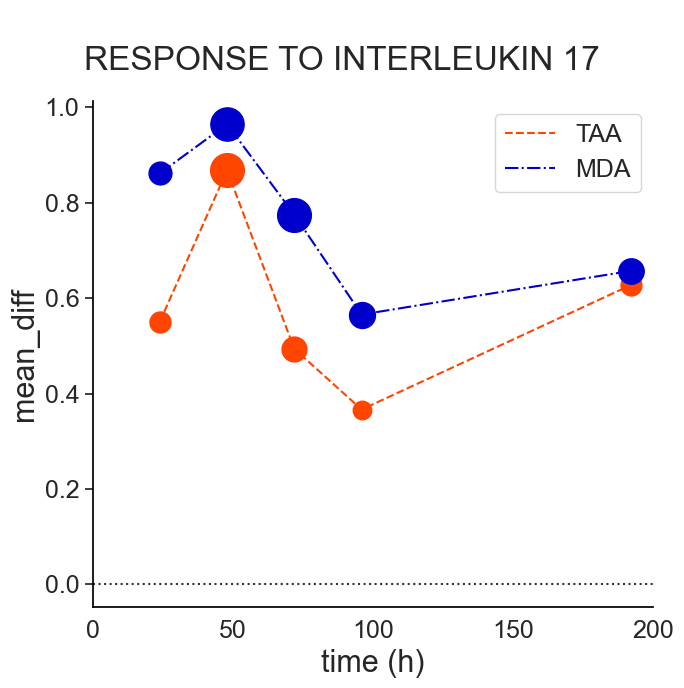

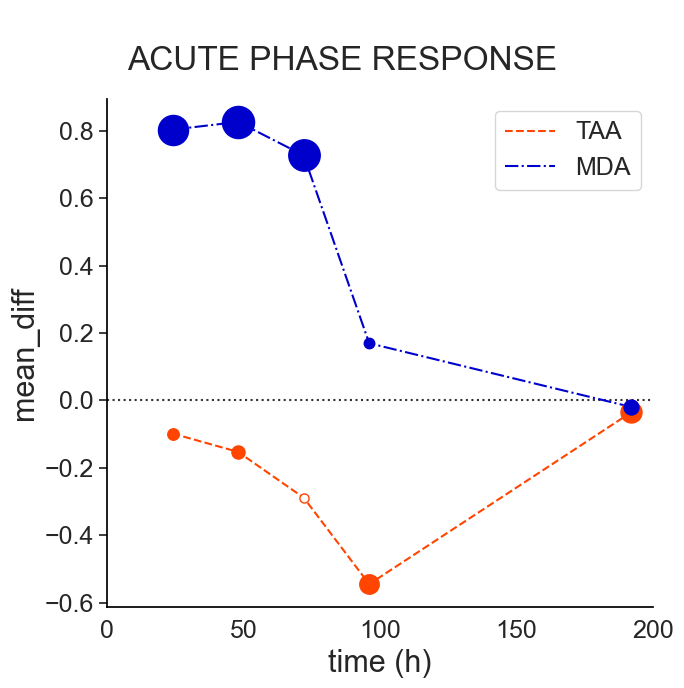

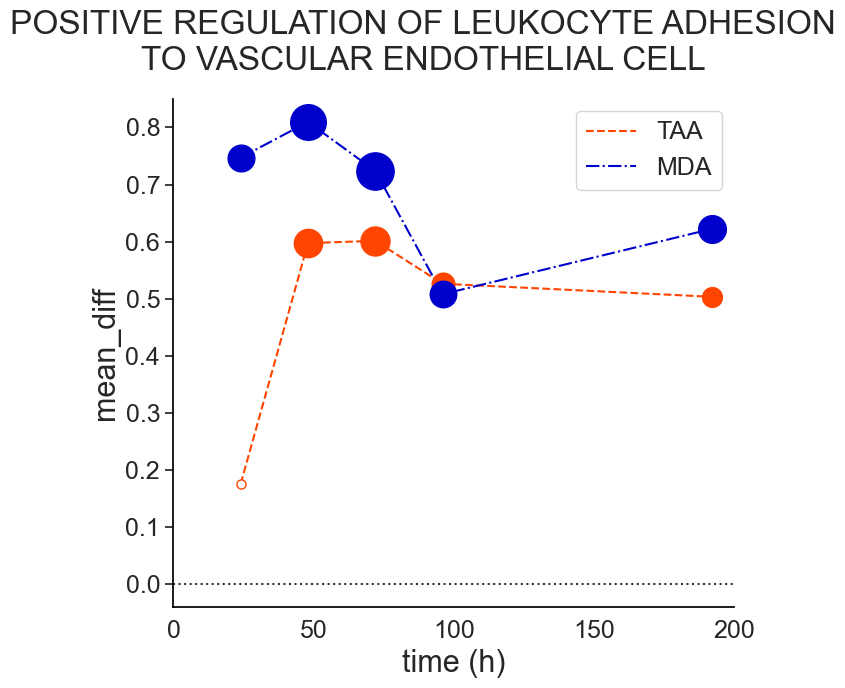

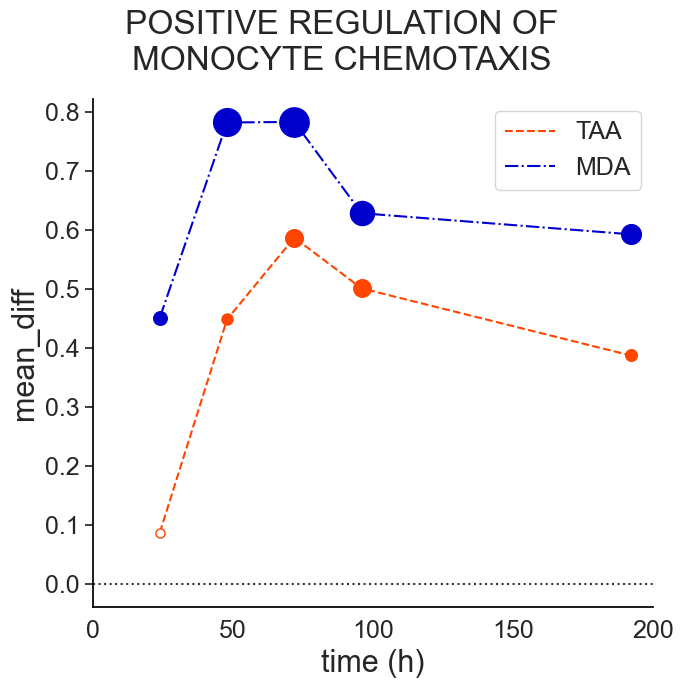

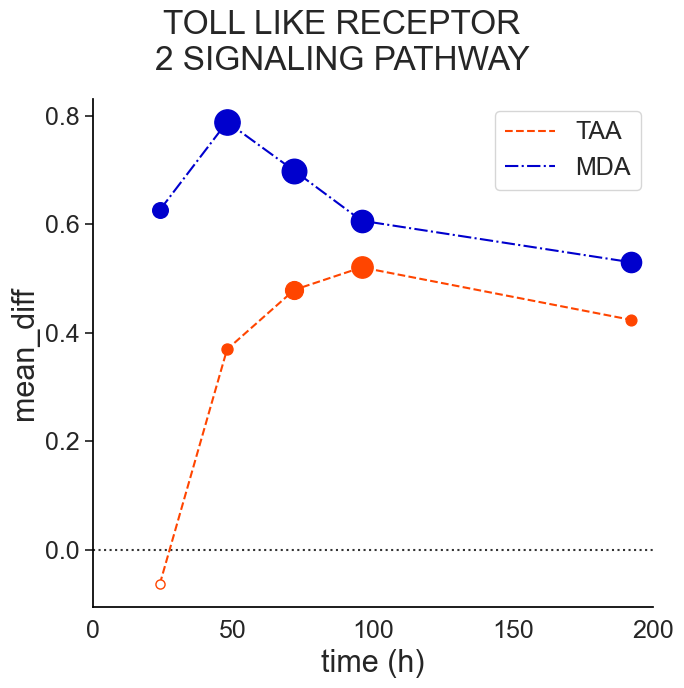

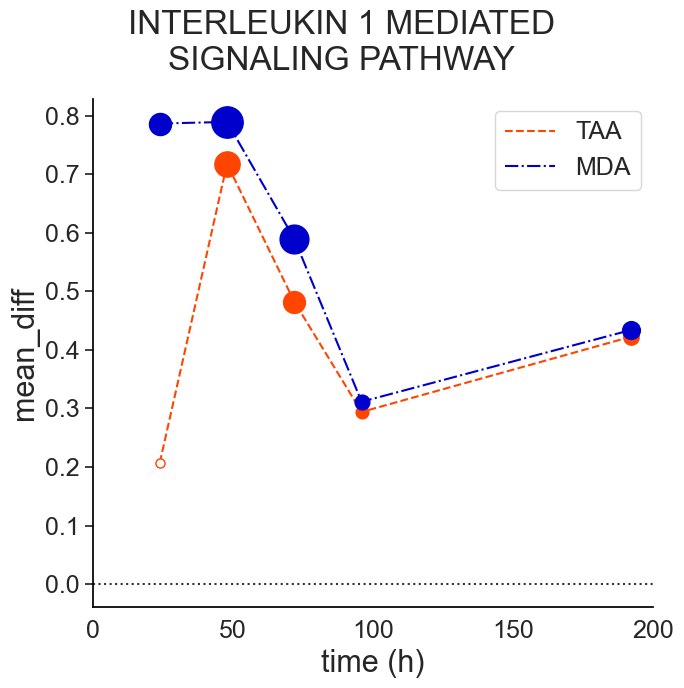

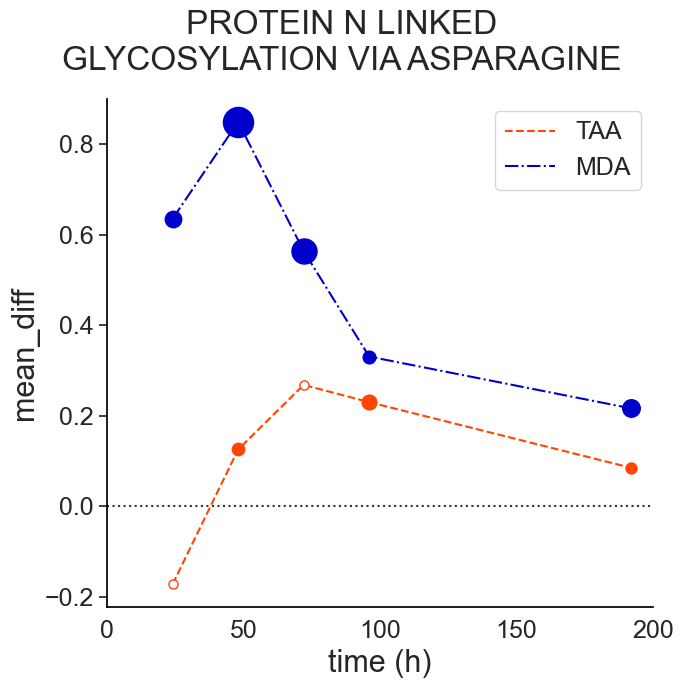

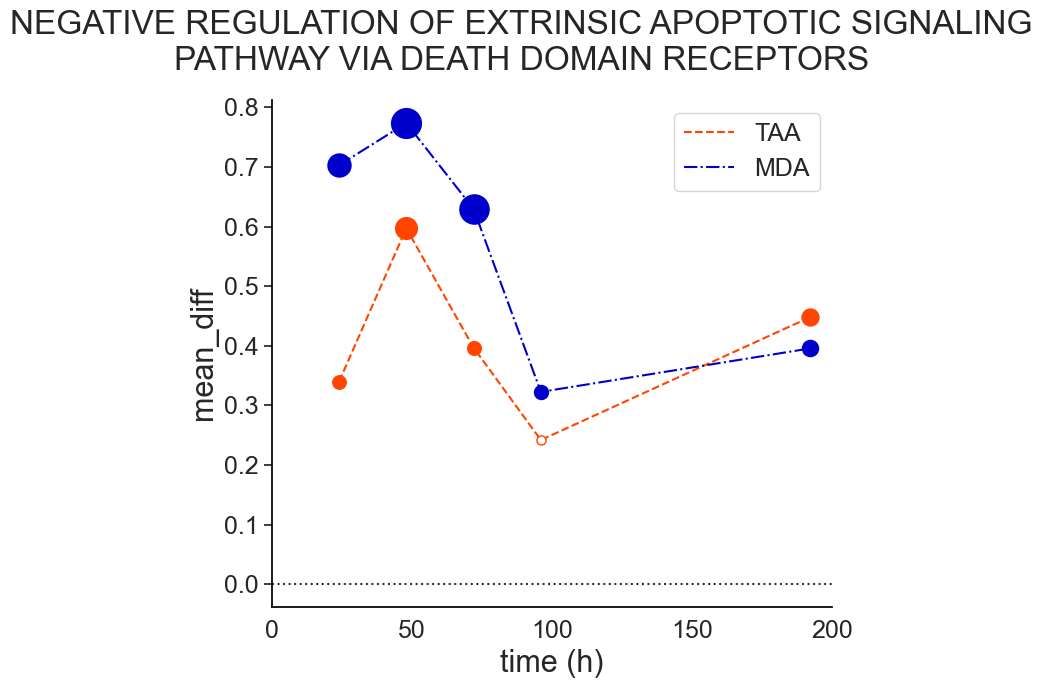

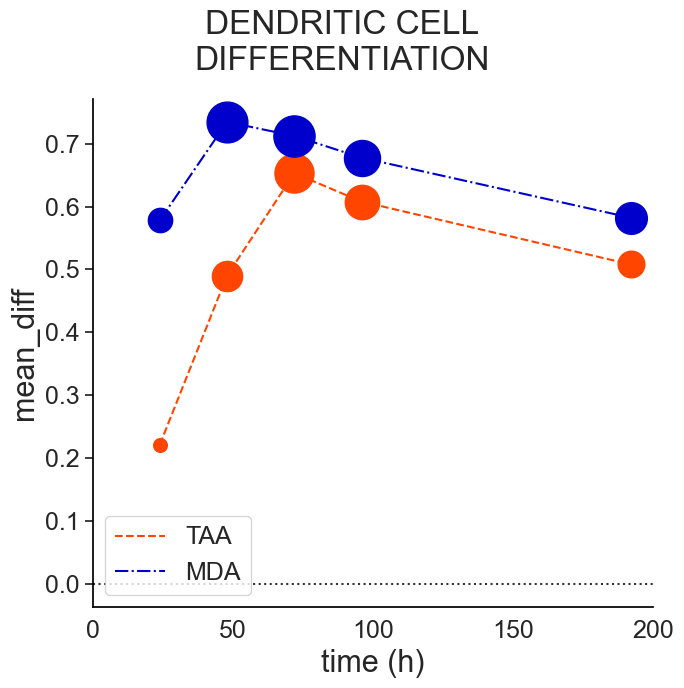

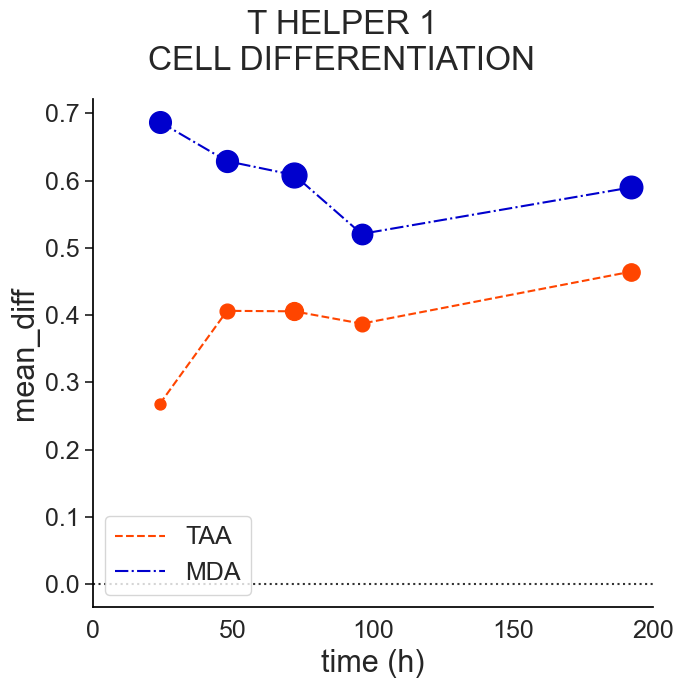

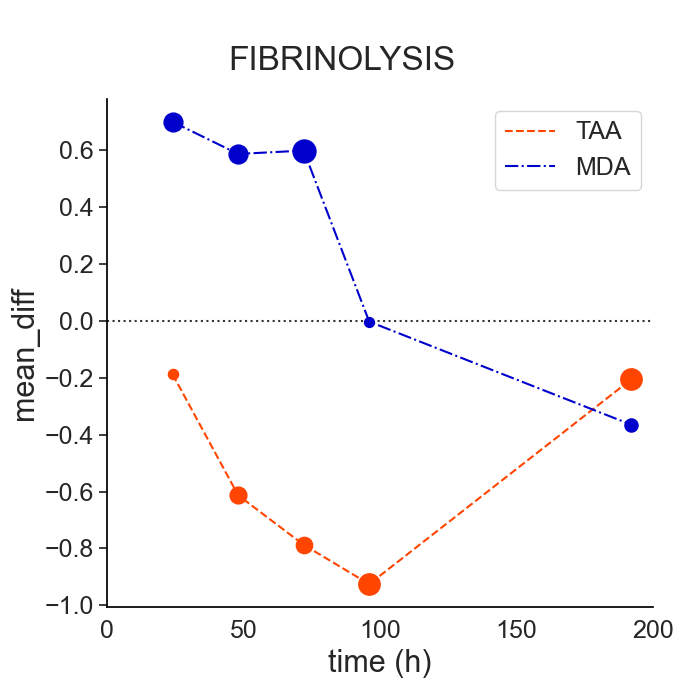

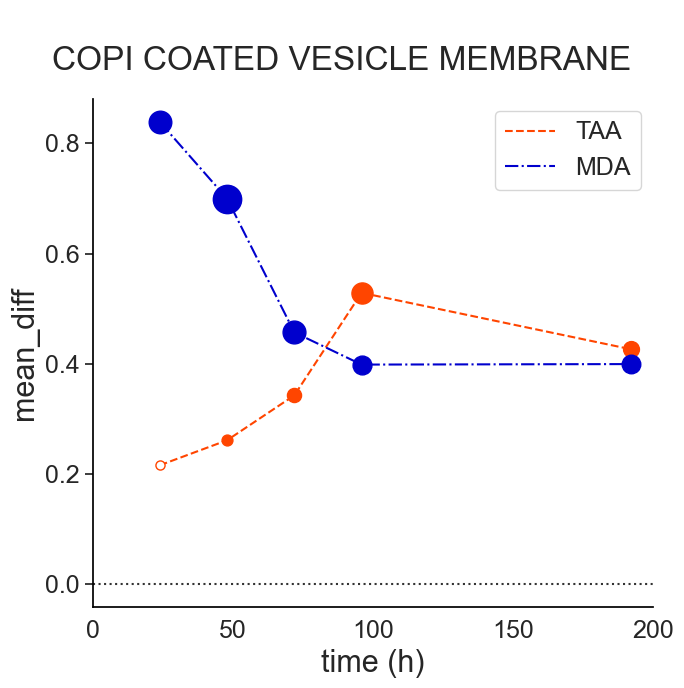

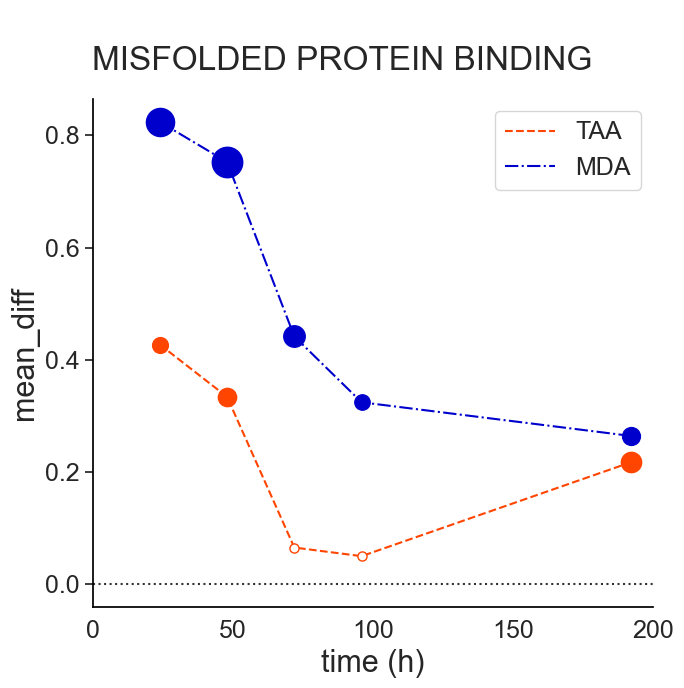

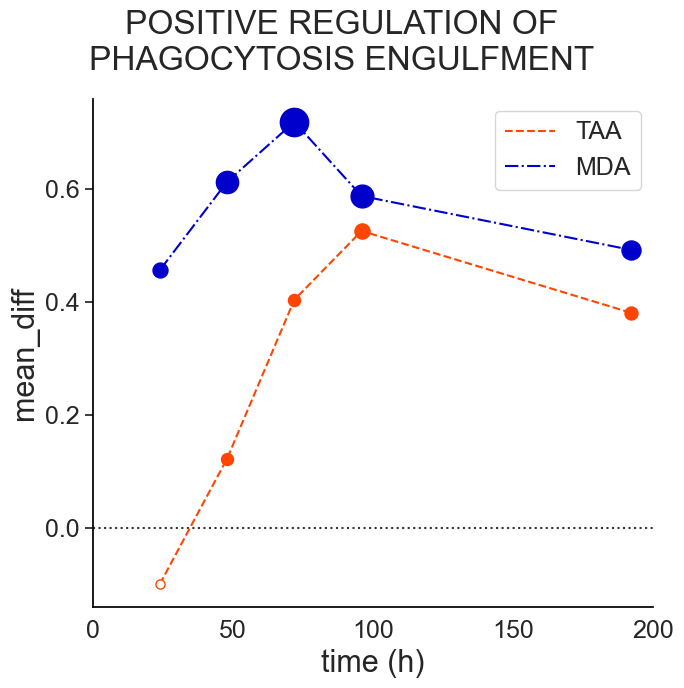

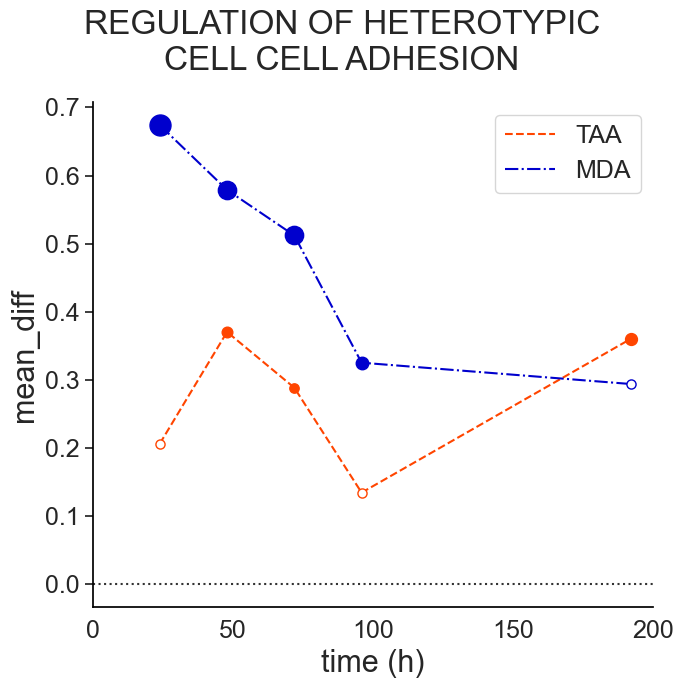

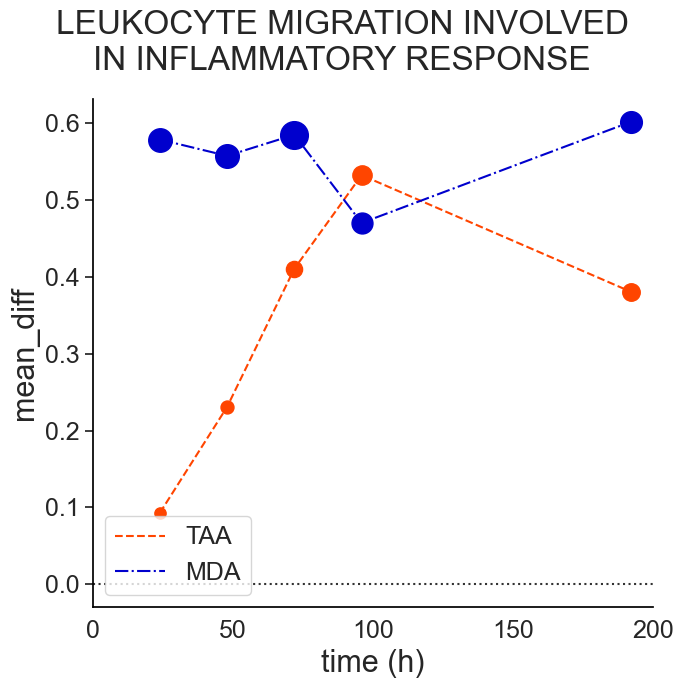

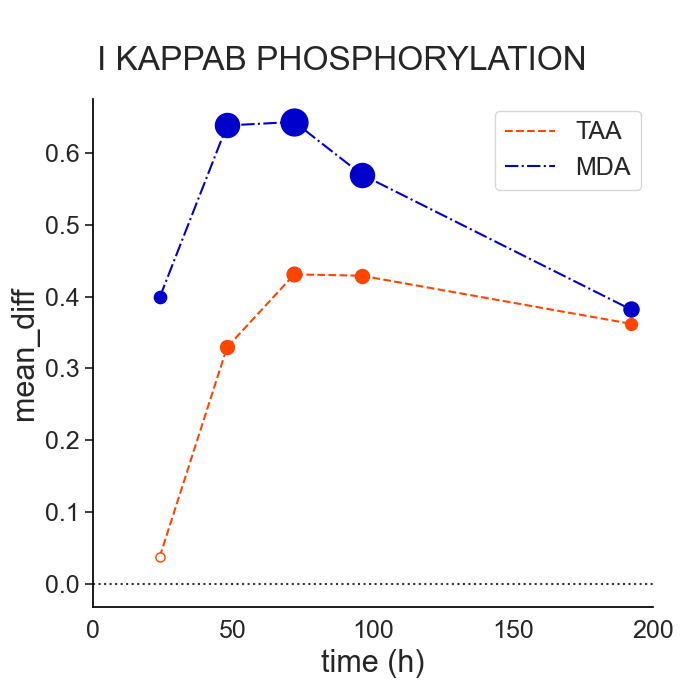

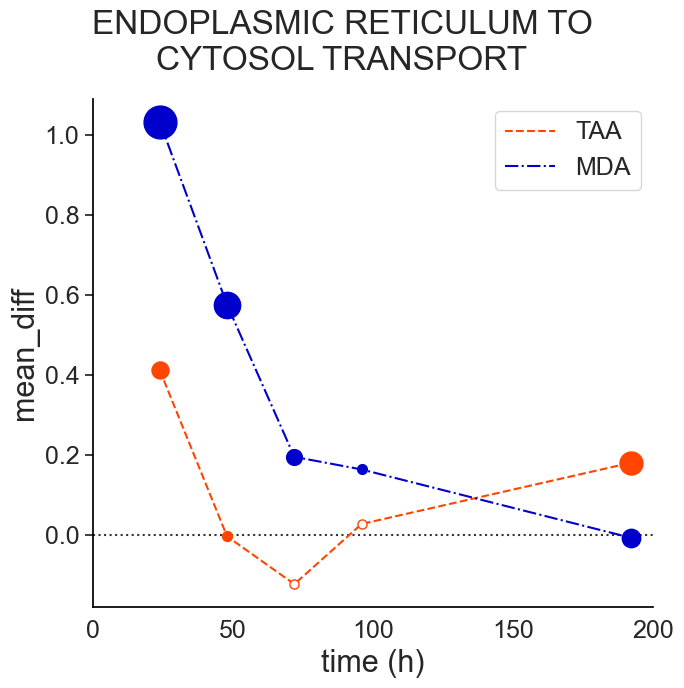

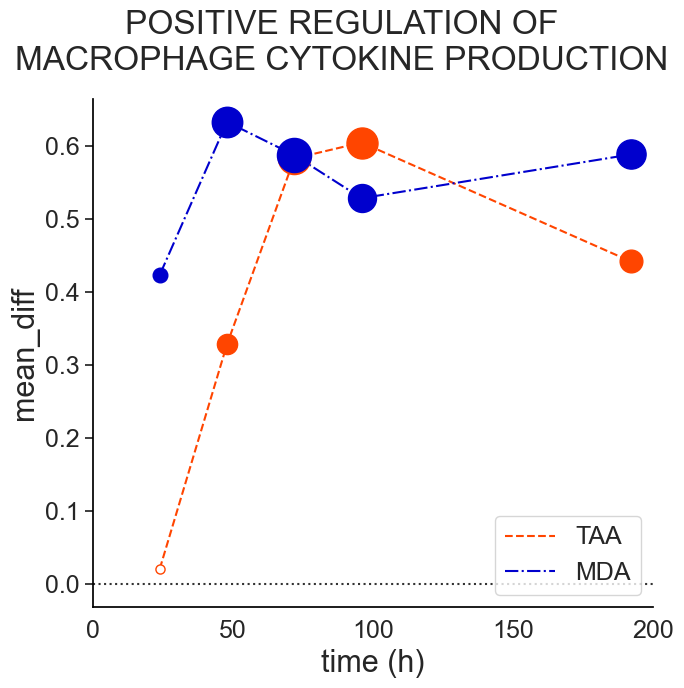

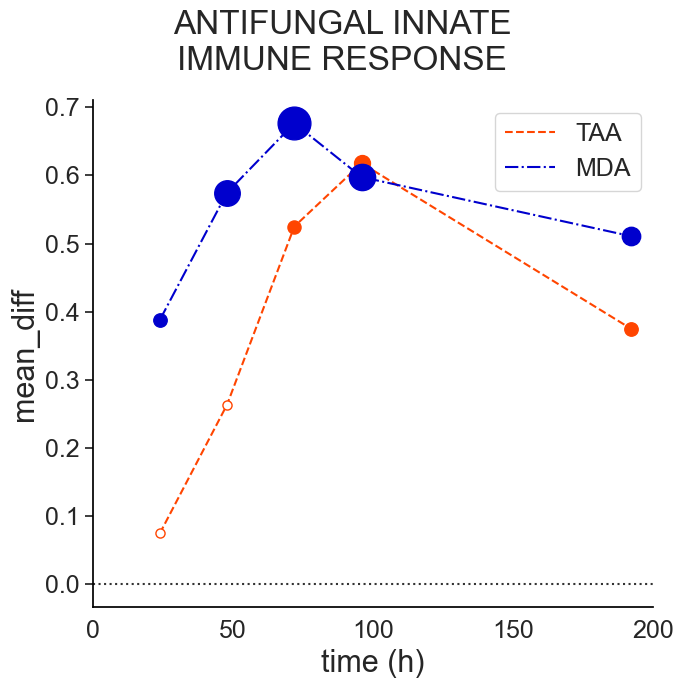

In [150]:
go_lst_pickup = golst_mda
for n, go in enumerate(go_lst_pickup):
    gage_plot(go, res_lst_v4, figname=None)

In [151]:
golst_mda

['GOBP_RESPONSE_TO_INTERLEUKIN_17',
 'GOBP_ACUTE_PHASE_RESPONSE',
 'GOBP_POSITIVE_REGULATION_OF_LEUKOCYTE_ADHESION_TO_VASCULAR_ENDOTHELIAL_CELL',
 'GOBP_POSITIVE_REGULATION_OF_MONOCYTE_CHEMOTAXIS',
 'GOBP_TOLL_LIKE_RECEPTOR_2_SIGNALING_PATHWAY',
 'GOBP_INTERLEUKIN_1_MEDIATED_SIGNALING_PATHWAY',
 'GOBP_PROTEIN_N_LINKED_GLYCOSYLATION_VIA_ASPARAGINE',
 'GOBP_NEGATIVE_REGULATION_OF_EXTRINSIC_APOPTOTIC_SIGNALING_PATHWAY_VIA_DEATH_DOMAIN_RECEPTORS',
 'GOBP_DENDRITIC_CELL_DIFFERENTIATION',
 'GOBP_T_HELPER_1_CELL_DIFFERENTIATION',
 'GOBP_FIBRINOLYSIS',
 'GOCC_COPI_COATED_VESICLE_MEMBRANE',
 'GOMF_MISFOLDED_PROTEIN_BINDING',
 'GOBP_POSITIVE_REGULATION_OF_PHAGOCYTOSIS_ENGULFMENT',
 'GOBP_REGULATION_OF_HETEROTYPIC_CELL_CELL_ADHESION',
 'GOBP_LEUKOCYTE_MIGRATION_INVOLVED_IN_INFLAMMATORY_RESPONSE',
 'GOBP_I_KAPPAB_PHOSPHORYLATION',
 'GOBP_ENDOPLASMIC_RETICULUM_TO_CYTOSOL_TRANSPORT',
 'GOBP_POSITIVE_REGULATION_OF_MACROPHAGE_CYTOKINE_PRODUCTION',
 'GOBP_ANTIFUNGAL_INNATE_IMMUNE_RESPONSE']

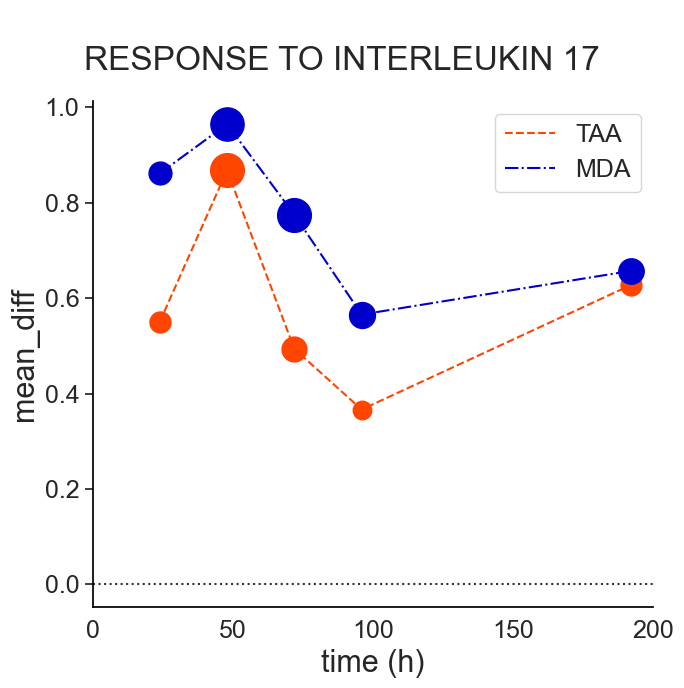

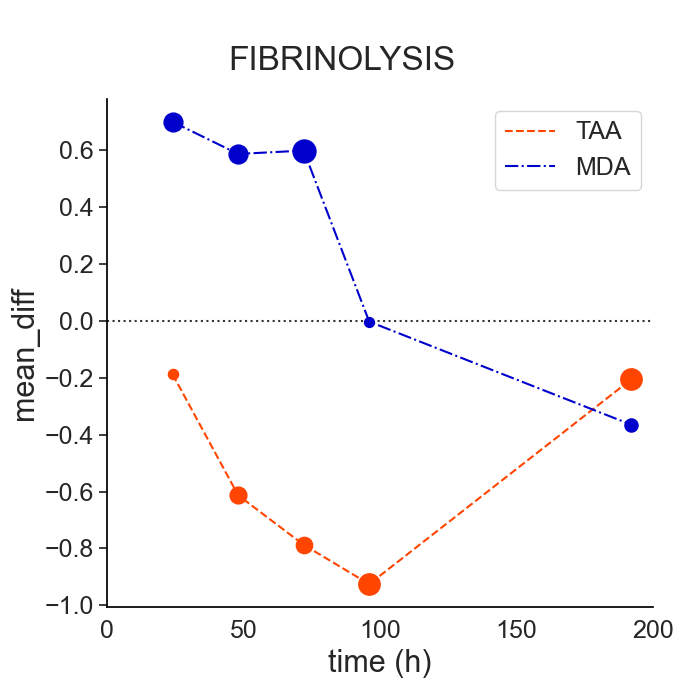

In [154]:
go_lst_pickup = ['GOBP_RESPONSE_TO_INTERLEUKIN_17', 'GOBP_FIBRINOLYSIS']
for n, go in enumerate(go_lst_pickup):
    fig_name = "fig7"+["a", "b"][n]+".png"
    name = f"{root}/{fig_name}"
    gage_plot(go, res_lst_v4, figname=name)